# DengueGuard — IJIES Major Revision Experiment Notebook

**Purpose.** This notebook implements the new analyses requested by the two IJIES reviewers for Paper ID **20267240**. It preserves the original DengueGuard data logic while adding the controls needed to distinguish the contribution of temporal convolution, variable gating, the auxiliary outbreak task, the negative-binomial likelihood, calibration, and historical input representation.

### Reviewer-to-analysis map

| Reviewer request | Notebook output |
|---|---|
| Matched plain TCN, ungated, count-only, Poisson-head ablations | `R1_ablation_metrics.csv`, `Fig_R1_ablation_MAE.png` |
| Exact split dates, retained counts, origin-target indices | `R2_split_audit.csv`, `R2_origin_target_manifest.csv` |
| Stronger matched historical baselines | `R3_baseline_metrics.csv`, tuning audit CSVs |
| City-aware moving-block bootstrap + multiplicity | `R4_block_bootstrap.csv` |
| NB log score, discrete CRPS, randomized PIT, NB intervals | `R5_probabilistic_scores.csv`, PIT figures |
| Pooled vs city-conditional vs adaptive calibration | `R6_interval_comparison.csv` |
| Outbreak Brier/log score, calibration, threshold sensitivity, risk baseline | `R7_outbreak_metrics.csv`, calibration figures |
| Layer shapes, GroupNorm, dropout, parameter count, receptive field | `R8_architecture_audit.csv` |
| Ordered 32-feature manifest + missingness + delay sensitivity | `R9_feature_manifest.csv`, `R9_delay_sensitivity.csv` |
| Immutable reproducibility artifact | final ZIP + SHA-256 manifest |
| Temporal replication of horizon crossover | `R2_temporal_replication_metrics.csv` and figures |

> **Important:** Run the final submission experiments with `QUICK_MODE = False`. `QUICK_MODE = True` is only for verifying that the notebook executes correctly.


In [ ]:
# Colab dependencies
!pip -q install numpy pandas scipy scikit-learn matplotlib pyyaml torch


In [ ]:
%%writefile dengueguard_revision.py
from __future__ import annotations

import copy
import hashlib
import itertools
import json
import math
import random
from dataclasses import dataclass
from pathlib import Path
from typing import Dict, Iterable, List, Optional, Sequence, Tuple

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from scipy.stats import nbinom, poisson
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.linear_model import LogisticRegression, PoissonRegressor
from sklearn.metrics import (
    average_precision_score,
    brier_score_loss,
    log_loss,
    mean_absolute_error,
    mean_squared_error,
    roc_auc_score,
)
from sklearn.preprocessing import StandardScaler
from torch.utils.data import DataLoader, Dataset

KEYS = ["city", "year", "weekofyear"]
HORIZONS_DEFAULT = [1, 2, 4, 8, 12]

RAW_FEATURE_UNITS = {
    "ndvi_ne": "NDVI (unitless)",
    "ndvi_nw": "NDVI (unitless)",
    "ndvi_se": "NDVI (unitless)",
    "ndvi_sw": "NDVI (unitless)",
    "precipitation_amt_mm": "mm/week",
    "reanalysis_air_temp_k": "K",
    "reanalysis_avg_temp_k": "K",
    "reanalysis_dew_point_temp_k": "K",
    "reanalysis_max_air_temp_k": "K",
    "reanalysis_min_air_temp_k": "K",
    "reanalysis_precip_amt_kg_per_m2": "kg/m^2",
    "reanalysis_relative_humidity_percent": "%",
    "reanalysis_sat_precip_amt_mm": "mm",
    "reanalysis_specific_humidity_g_per_kg": "g/kg",
    "reanalysis_tdtr_k": "K",
    "station_avg_temp_c": "deg C",
    "station_diur_temp_rng_c": "deg C",
    "station_max_temp_c": "deg C",
    "station_min_temp_c": "deg C",
    "station_precip_mm": "mm/week",
}

ENGINEERED_UNITS = {
    "week_sin": "unitless",
    "week_cos": "unitless",
    "city_code": "categorical code",
    "cases_lag_1": "cases",
    "cases_lag_2": "cases",
    "cases_lag_4": "cases",
    "cases_lag_8": "cases",
    "cases_lag_12": "cases",
    "cases_lag_26": "cases",
    "cases_lag_52": "cases",
    "cases_roll4": "cases",
    "cases_roll12": "cases",
}


@dataclass
class Sample:
    city: str
    origin_index: int
    origin_year: int
    origin_week: int
    origin_date: Optional[str]
    target_indices: Tuple[int, ...]
    target_dates: Tuple[Optional[str], ...]
    split: str
    fold: int
    x: np.ndarray
    y: np.ndarray
    outbreak: np.ndarray
    seasonal: np.ndarray
    persistence: np.ndarray


def set_seed(seed: int) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


def locate_pair(data_dir: Path) -> Tuple[Path, Path]:
    pairs = [
        ("dengue_features_train.csv", "dengue_labels_train.csv"),
        ("train_features.csv", "train_labels.csv"),
    ]
    for fx, fy in pairs:
        if (data_dir / fx).exists() and (data_dir / fy).exists():
            return data_dir / fx, data_dir / fy
    raise FileNotFoundError(f"Expected one of these DengAI pairs under {data_dir}: {pairs}")


def load_data(data_dir: Path) -> pd.DataFrame:
    feature_path, label_path = locate_pair(data_dir)
    features = pd.read_csv(feature_path)
    labels = pd.read_csv(label_path)
    missing = set(KEYS) - set(features.columns)
    if missing or "total_cases" not in labels.columns:
        raise ValueError(f"Unexpected schema; missing keys={sorted(missing)} or total_cases")
    frame = features.merge(labels[KEYS + ["total_cases"]], on=KEYS, how="inner", validate="one_to_one")
    if "week_start_date" in frame.columns:
        frame["week_start_date"] = pd.to_datetime(frame["week_start_date"], errors="coerce")
    frame = frame.sort_values(KEYS).reset_index(drop=True)
    if frame.duplicated(KEYS).any():
        raise ValueError("Duplicate city-year-week records detected")
    return frame


def _feature_group(name: str) -> str:
    if name.startswith("cases_"):
        return "incidence history"
    if name in {"week_sin", "week_cos"}:
        return "seasonality"
    if name == "city_code":
        return "location"
    if name.startswith("ndvi_"):
        return "vegetation"
    if any(k in name for k in ["temp", "humidity", "precip", "tdtr"]):
        return "meteorology"
    return "other"


def engineer_frame(
    frame: pd.DataFrame,
    case_reporting_delay_weeks: int = 0,
    environmental_delay_weeks: int = 0,
) -> Tuple[pd.DataFrame, List[str]]:
    """Create leakage-safe features.

    case_reporting_delay_weeks=1 means the latest case report available at issue time
    is one additional week older than in the primary analysis.
    environmental_delay_weeks similarly shifts raw environmental covariates by city.
    """
    df = frame.copy()
    df["week_sin"] = np.sin(2 * np.pi * df["weekofyear"].astype(float) / 52.0)
    df["week_cos"] = np.cos(2 * np.pi * df["weekofyear"].astype(float) / 52.0)
    df["city_code"] = pd.Categorical(df["city"]).codes.astype(float)

    excluded = set(KEYS + ["week_start_date", "total_cases"])
    numeric = [c for c in df.columns if c not in excluded and pd.api.types.is_numeric_dtype(df[c])]

    if environmental_delay_weeks > 0:
        for city, idx in df.groupby("city", sort=False).groups.items():
            ordered = list(idx)
            for c in numeric:
                df.loc[ordered, c] = df.loc[ordered, c].shift(environmental_delay_weeks).to_numpy()

    for city, idx in df.groupby("city", sort=False).groups.items():
        ordered = list(idx)
        base_shift = int(case_reporting_delay_weeks)
        for lag in (1, 2, 4, 8, 12, 26, 52):
            df.loc[ordered, f"cases_lag_{lag}"] = (
                df.loc[ordered, "total_cases"].shift(lag + base_shift).to_numpy()
            )
        df.loc[ordered, "cases_roll4"] = (
            df.loc[ordered, "total_cases"]
            .shift(1 + base_shift)
            .rolling(4)
            .mean()
            .to_numpy()
        )
        df.loc[ordered, "cases_roll12"] = (
            df.loc[ordered, "total_cases"]
            .shift(1 + base_shift)
            .rolling(12)
            .mean()
            .to_numpy()
        )

    feature_cols = numeric + [
        "week_sin", "week_cos", "city_code", "cases_lag_1", "cases_lag_2",
        "cases_lag_4", "cases_lag_8", "cases_lag_12", "cases_lag_26",
        "cases_lag_52", "cases_roll4", "cases_roll12",
    ]
    feature_cols = list(dict.fromkeys(feature_cols))
    return df, feature_cols


def feature_manifest(raw: pd.DataFrame, engineered: pd.DataFrame, feature_cols: Sequence[str]) -> pd.DataFrame:
    rows = []
    for order, c in enumerate(feature_cols, start=1):
        source = "engineered" if c in ENGINEERED_UNITS else "DengAI weekly feature"
        units = ENGINEERED_UNITS.get(c, RAW_FEATURE_UNITS.get(c, "dataset-defined / unitless"))
        if c in raw.columns:
            miss = float(raw[c].isna().mean())
        else:
            miss = float(engineered[c].isna().mean())
        if c.startswith("cases_lag_"):
            definition = f"weekly total_cases shifted by {c.split('_')[-1]} week(s)"
        elif c == "cases_roll4":
            definition = "mean of previous 4 reported weekly case counts, shifted before aggregation"
        elif c == "cases_roll12":
            definition = "mean of previous 12 reported weekly case counts, shifted before aggregation"
        elif c == "week_sin":
            definition = "sin(2*pi*weekofyear/52)"
        elif c == "week_cos":
            definition = "cos(2*pi*weekofyear/52)"
        elif c == "city_code":
            definition = "numeric code for city"
        else:
            definition = "weekly value supplied by the DengAI benchmark"
        availability_note = (
            "derived from surveillance history available before forecast origin"
            if c.startswith("cases_")
            else "retrospective benchmark value; real-time release/revision latency is not encoded"
        )
        rows.append({
            "order": order,
            "feature": c,
            "group": _feature_group(c),
            "units": units,
            "source": source,
            "definition": definition,
            "missing_fraction_before_imputation": miss,
            "forecast_issue_availability": availability_note,
        })
    return pd.DataFrame(rows)


def split_boundaries_fraction(n: int, cfg: dict) -> Tuple[int, int, int, int]:
    train_end = int(n * float(cfg["train_fraction"]))
    val_end = train_end + int(n * float(cfg["validation_fraction"]))
    cal_end = val_end + int(n * float(cfg["calibration_fraction"]))
    test_end = n
    if not (0 < train_end < val_end < cal_end < test_end):
        raise ValueError(f"Invalid chronological split for n={n}")
    return train_end, val_end, cal_end, test_end


def rolling_boundaries(n: int, fold: int, test_len: int = 52, cal_len: int = 52, val_len: int = 26, step: int = 52):
    """Expanding-window, non-overlapping test folds. fold=0 is latest fold."""
    test_end = n - fold * step
    test_start = test_end - test_len
    cal_end = test_start
    cal_start = cal_end - cal_len
    val_end = cal_start
    val_start = val_end - val_len
    train_end = val_start
    if train_end <= 80:
        raise ValueError(f"Insufficient history for fold={fold}, n={n}")
    return train_end, val_end, cal_end, test_end


def _date_str(value) -> Optional[str]:
    if pd.isna(value):
        return None
    try:
        return pd.Timestamp(value).date().isoformat()
    except Exception:
        return str(value)


def build_samples(
    df: pd.DataFrame,
    feature_cols: List[str],
    cfg: dict,
    fold: int = 0,
    boundaries_by_city: Optional[Dict[str, Tuple[int, int, int, int]]] = None,
) -> Tuple[List[Sample], Dict[str, float], pd.DataFrame, pd.DataFrame]:
    lookback = int(cfg["lookback"])
    horizons = [int(h) for h in cfg["horizons"]]
    max_h = max(horizons)
    samples: List[Sample] = []
    thresholds: Dict[str, float] = {}
    split_rows = []
    index_rows = []

    for city, part in df.groupby("city", sort=True):
        part = part.sort_values(["year", "weekofyear"]).reset_index(drop=True)
        n = len(part)
        if boundaries_by_city is None:
            train_end, val_end, cal_end, test_end = split_boundaries_fraction(n, cfg)
        else:
            train_end, val_end, cal_end, test_end = boundaries_by_city[str(city)]

        threshold = float(
            part.loc[: train_end - 1, "total_cases"].quantile(
                float(cfg["outbreak_quantile"]), interpolation="linear"
            )
        )
        thresholds[str(city)] = threshold
        targets = part["total_cases"].to_numpy(dtype=np.float32)

        def boundary_date(idx, side="start"):
            if "week_start_date" not in part.columns:
                return None
            idx = max(0, min(idx, n - 1))
            return _date_str(part.loc[idx, "week_start_date"])

        split_rows.append({
            "fold": fold,
            "city": str(city),
            "n_city_weeks": n,
            "train_index_start": 0,
            "train_index_end_exclusive": train_end,
            "validation_index_start": train_end,
            "validation_index_end_exclusive": val_end,
            "calibration_index_start": val_end,
            "calibration_index_end_exclusive": cal_end,
            "test_index_start": cal_end,
            "test_index_end_exclusive": test_end,
            "train_start_date": boundary_date(0),
            "train_end_date": boundary_date(train_end - 1),
            "validation_start_date": boundary_date(train_end),
            "validation_end_date": boundary_date(val_end - 1),
            "calibration_start_date": boundary_date(val_end),
            "calibration_end_date": boundary_date(cal_end - 1),
            "test_start_date": boundary_date(cal_end),
            "test_end_date": boundary_date(test_end - 1),
            "outbreak_threshold": threshold,
            "outbreak_operator": ">=",
            "quantile_rule": "pandas linear interpolation",
        })

        for origin in range(lookback, test_end - max_h + 1):
            final_target = origin + max_h - 1
            if final_target < train_end:
                split = "train"
            elif origin >= train_end and final_target < val_end:
                split = "validation"
            elif origin >= val_end and final_target < cal_end:
                split = "calibration"
            elif origin >= cal_end and final_target < test_end:
                split = "test"
            else:
                continue

            target_indices = tuple(origin + h - 1 for h in horizons)
            y = np.asarray([targets[k] for k in target_indices], dtype=np.float32)
            seasonal = np.asarray([
                targets[k - 52] if k - 52 >= 0 else targets[origin - 1]
                for k in target_indices
            ], dtype=np.float32)
            persistence = np.repeat(targets[origin - 1], len(horizons)).astype(np.float32)
            x = part.loc[origin - lookback : origin - 1, feature_cols].to_numpy(dtype=np.float32)
            origin_date = _date_str(part.loc[origin, "week_start_date"]) if "week_start_date" in part.columns else None
            target_dates = tuple(
                _date_str(part.loc[k, "week_start_date"]) if "week_start_date" in part.columns else None
                for k in target_indices
            )
            s = Sample(
                city=str(city), origin_index=int(origin), origin_year=int(part.loc[origin, "year"]),
                origin_week=int(part.loc[origin, "weekofyear"]), origin_date=origin_date,
                target_indices=target_indices, target_dates=target_dates,
                split=split, fold=int(fold), x=x, y=y,
                outbreak=(y >= threshold).astype(np.float32),
                seasonal=seasonal, persistence=persistence,
            )
            samples.append(s)
            for j, h in enumerate(horizons):
                index_rows.append({
                    "fold": fold, "city": str(city), "split": split,
                    "origin_index": origin, "origin_year": int(part.loc[origin, "year"]),
                    "origin_week": int(part.loc[origin, "weekofyear"]), "origin_date": origin_date,
                    "horizon": int(h), "target_index": target_indices[j], "target_date": target_dates[j],
                    "target_cases": float(y[j]), "outbreak": int(y[j] >= threshold),
                    "history_start_index": origin - lookback, "history_end_index": origin - 1,
                })

    split_audit = pd.DataFrame(split_rows)
    index_manifest = pd.DataFrame(index_rows)
    retained = (
        index_manifest.drop_duplicates(["fold", "city", "split", "origin_index"])
        .groupby(["fold", "city", "split"]).size().rename("retained_origins").reset_index()
    )
    split_audit = split_audit.merge(
        retained.pivot_table(index=["fold", "city"], columns="split", values="retained_origins", fill_value=0).reset_index(),
        on=["fold", "city"], how="left"
    )
    return samples, thresholds, split_audit, index_manifest


def impute_and_scale(samples: List[Sample]) -> Tuple[List[Sample], StandardScaler, np.ndarray]:
    samples = copy.deepcopy(samples)
    train_rows = np.concatenate([s.x for s in samples if s.split == "train"], axis=0)
    medians = np.nanmedian(train_rows, axis=0)
    medians = np.where(np.isfinite(medians), medians, 0.0)
    clean_train = np.where(np.isfinite(train_rows), train_rows, medians)
    scaler = StandardScaler().fit(clean_train)
    for s in samples:
        clean = np.where(np.isfinite(s.x), s.x, medians)
        s.x = scaler.transform(clean).astype(np.float32)
    return samples, scaler, medians


def subset_samples(samples: List[Sample], feature_indices: Sequence[int]) -> List[Sample]:
    out = copy.deepcopy(samples)
    idx = np.asarray(feature_indices, dtype=int)
    for s in out:
        s.x = s.x[:, idx]
    return out


class SequenceDataset(Dataset):
    def __init__(self, samples: Sequence[Sample]):
        self.samples = list(samples)
    def __len__(self):
        return len(self.samples)
    def __getitem__(self, i):
        s = self.samples[i]
        return torch.from_numpy(s.x), torch.from_numpy(s.y), torch.from_numpy(s.outbreak)


class VariableGate(nn.Module):
    def __init__(self, features: int, hidden: int):
        super().__init__()
        self.score = nn.Sequential(nn.Linear(features, hidden), nn.GELU(), nn.Linear(hidden, features))
    def forward(self, x):
        w = torch.softmax(self.score(x), dim=-1)
        return x * w * x.shape[-1], w


class GatedCausalResidualBlock(nn.Module):
    def __init__(self, hidden: int, kernel: int, dilation: int, dropout: float):
        super().__init__()
        self.pad = (kernel - 1) * dilation
        self.conv = nn.Conv1d(hidden, 2 * hidden, kernel, padding=self.pad, dilation=dilation)
        self.norm = nn.GroupNorm(1, hidden)
        self.dropout = nn.Dropout(dropout)
    def forward(self, x):
        z = self.conv(x)
        if self.pad:
            z = z[..., :-self.pad]
        a, b = z.chunk(2, dim=1)
        z = torch.tanh(a) * torch.sigmoid(b)
        return self.norm(x + self.dropout(z))


class PlainCausalResidualBlock(nn.Module):
    def __init__(self, hidden: int, kernel: int, dilation: int, dropout: float):
        super().__init__()
        self.pad = (kernel - 1) * dilation
        self.conv = nn.Conv1d(hidden, hidden, kernel, padding=self.pad, dilation=dilation)
        self.norm = nn.GroupNorm(1, hidden)
        self.dropout = nn.Dropout(dropout)
    def forward(self, x):
        z = self.conv(x)
        if self.pad:
            z = z[..., :-self.pad]
        z = F.gelu(z)
        return self.norm(x + self.dropout(z))


class TemporalForecastModel(nn.Module):
    def __init__(
        self, features: int, horizons: int, cfg: dict,
        use_variable_gate: bool = True,
        gated_blocks: bool = True,
        count_distribution: str = "negative_binomial",
        use_outbreak_head: bool = True,
    ):
        super().__init__()
        hidden = int(cfg["hidden_size"])
        self.features = features
        self.horizons = horizons
        self.use_variable_gate = use_variable_gate
        self.count_distribution = count_distribution
        self.use_outbreak_head = use_outbreak_head
        self.gate = VariableGate(features, hidden) if use_variable_gate else None
        self.project = nn.Linear(features, hidden)
        block_cls = GatedCausalResidualBlock if gated_blocks else PlainCausalResidualBlock
        self.blocks = nn.ModuleList([
            block_cls(hidden, int(cfg["kernel_size"]), int(d), float(cfg["dropout"]))
            for d in cfg["dilations"]
        ])
        self.pool = nn.Sequential(nn.Linear(hidden, hidden), nn.Tanh())
        self.mu = nn.Linear(hidden, horizons)
        self.dispersion = nn.Linear(hidden, horizons) if count_distribution == "negative_binomial" else None
        self.outbreak = nn.Linear(hidden, horizons) if use_outbreak_head else None

    def forward(self, x):
        if self.gate is not None:
            x, weights = self.gate(x)
        else:
            weights = torch.full_like(x, 1.0 / x.shape[-1])
        z = self.project(x).transpose(1, 2)
        for block in self.blocks:
            z = block(z)
        state = self.pool(z[..., -1])
        mu = F.softplus(self.mu(state)) + 1e-4
        disp = F.softplus(self.dispersion(state)) + 1e-4 if self.dispersion is not None else torch.full_like(mu, float("nan"))
        logits = self.outbreak(state) if self.outbreak is not None else torch.full_like(mu, float("nan"))
        return mu, disp, logits, weights


class GRUForecastModel(nn.Module):
    def __init__(self, features: int, horizons: int, hidden: int = 64, dropout: float = 0.2, use_outbreak_head: bool = True):
        super().__init__()
        self.use_outbreak_head = use_outbreak_head
        self.gru = nn.GRU(features, hidden, num_layers=1, batch_first=True)
        self.dropout = nn.Dropout(dropout)
        self.mu = nn.Linear(hidden, horizons)
        self.dispersion = nn.Linear(hidden, horizons)
        self.outbreak = nn.Linear(hidden, horizons) if use_outbreak_head else None
    def forward(self, x):
        _, h = self.gru(x)
        state = self.dropout(h[-1])
        mu = F.softplus(self.mu(state)) + 1e-4
        disp = F.softplus(self.dispersion(state)) + 1e-4
        logits = self.outbreak(state) if self.outbreak is not None else torch.full_like(mu, float("nan"))
        weights = torch.full_like(x, 1.0 / x.shape[-1])
        return mu, disp, logits, weights


def negative_binomial_nll_elementwise(y, mu, dispersion):
    r = dispersion
    p = r / (r + mu)
    return -(
        torch.lgamma(y + r) - torch.lgamma(r) - torch.lgamma(y + 1)
        + r * torch.log(p.clamp_min(1e-8))
        + y * torch.log((1 - p).clamp_min(1e-8))
    )


def count_loss(y, mu, dispersion, distribution: str):
    if distribution == "negative_binomial":
        return negative_binomial_nll_elementwise(y, mu, dispersion).mean()
    if distribution == "poisson":
        return F.poisson_nll_loss(mu, y, log_input=False, full=True, reduction="mean")
    raise ValueError(distribution)


def parameter_count(model: nn.Module) -> int:
    return sum(p.numel() for p in model.parameters() if p.requires_grad)


def model_shape_manifest(model: nn.Module, feature_count: int, lookback: int, horizons: int) -> pd.DataFrame:
    rows = [
        {"component": "input", "shape": f"batch x {lookback} x {feature_count}", "details": "standardized weekly feature sequence"},
    ]
    if getattr(model, "gate", None) is not None:
        hidden = model.gate.score[0].out_features
        rows.append({"component": "variable gate", "shape": f"{feature_count} -> {hidden} -> {feature_count}", "details": "softmax over feature axis at each time step"})
    if hasattr(model, "project"):
        hidden = model.project.out_features
        rows.append({"component": "projection", "shape": f"{feature_count} -> {hidden}", "details": "applied per time step"})
        for i, block in enumerate(model.blocks):
            groups = block.norm.num_groups
            channels = block.norm.num_channels
            rows.append({"component": f"temporal block {i+1}", "shape": f"batch x {hidden} x {lookback}", "details": f"dilation={block.conv.dilation[0]}; kernel={block.conv.kernel_size[0]}; GroupNorm groups={groups}, channels={channels}; dropout after block activation before residual addition"})
        rows.append({"component": "shared state", "shape": f"batch x {hidden}", "details": "last causal temporal position -> linear+tanh"})
    elif hasattr(model, "gru"):
        rows.append({"component": "GRU", "shape": f"batch x {lookback} x {model.gru.hidden_size}", "details": "final hidden state used"})
    rows.append({"component": "count mean head", "shape": f"state -> {horizons}", "details": "softplus positive mean"})
    if getattr(model, "dispersion", None) is not None:
        rows.append({"component": "dispersion head", "shape": f"state -> {horizons}", "details": "softplus positive NB dispersion"})
    if getattr(model, "outbreak", None) is not None:
        rows.append({"component": "outbreak head", "shape": f"state -> {horizons}", "details": "logits -> sigmoid probability"})
    rows.append({"component": "trainable parameters", "shape": str(parameter_count(model)), "details": "exact count from instantiated model"})
    return pd.DataFrame(rows)


def nominal_conv_receptive_field(kernel_size: int, dilations: Sequence[int]) -> int:
    return 1 + (kernel_size - 1) * int(sum(dilations))


def train_neural_model(
    samples: List[Sample], model: nn.Module, cfg: dict, seed: int, device: torch.device,
    count_distribution: str = "negative_binomial", use_outbreak_loss: bool = True,
) -> Tuple[nn.Module, pd.DataFrame]:
    set_seed(seed)
    model = model.to(device)
    train = [s for s in samples if s.split == "train"]
    val = [s for s in samples if s.split == "validation"]
    train_loader = DataLoader(SequenceDataset(train), batch_size=int(cfg["training"]["batch_size"]), shuffle=True)
    val_loader = DataLoader(SequenceDataset(val), batch_size=256, shuffle=False)
    optimizer = torch.optim.AdamW(model.parameters(), lr=float(cfg["training"]["learning_rate"]), weight_decay=float(cfg["training"]["weight_decay"]))
    best_state, best_loss, best_epoch, stale = None, float("inf"), -1, 0
    history = []
    for epoch in range(1, int(cfg["training"]["epochs"]) + 1):
        model.train(); train_losses = []
        for x, y, outbreak in train_loader:
            x, y, outbreak = x.to(device), y.to(device), outbreak.to(device)
            mu, disp, logits, _ = model(x)
            loss = count_loss(y, mu, disp, count_distribution)
            if use_outbreak_loss:
                loss = loss + float(cfg["training"]["outbreak_loss_weight"]) * F.binary_cross_entropy_with_logits(logits, outbreak)
            optimizer.zero_grad(set_to_none=True)
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 5.0)
            optimizer.step()
            train_losses.append(float(loss.detach().cpu()))
        model.eval(); val_losses = []
        with torch.no_grad():
            for x, y, outbreak in val_loader:
                x, y, outbreak = x.to(device), y.to(device), outbreak.to(device)
                mu, disp, logits, _ = model(x)
                loss = count_loss(y, mu, disp, count_distribution)
                if use_outbreak_loss:
                    loss = loss + float(cfg["training"]["outbreak_loss_weight"]) * F.binary_cross_entropy_with_logits(logits, outbreak)
                val_losses.append(float(loss.cpu()))
        current = float(np.mean(val_losses))
        history.append({"epoch": epoch, "train_loss": float(np.mean(train_losses)), "validation_loss": current})
        if current < best_loss - 1e-5:
            best_loss, best_epoch, stale = current, epoch, 0
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        else:
            stale += 1
        if stale >= int(cfg["training"]["patience"]):
            break
    if best_state is None:
        raise RuntimeError("Training failed to produce checkpoint")
    model.load_state_dict(best_state)
    hist = pd.DataFrame(history)
    hist.attrs["best_epoch"] = best_epoch
    hist.attrs["best_validation_loss"] = best_loss
    return model, hist


def predict_neural(model: nn.Module, samples: Sequence[Sample], device: torch.device):
    model.eval(); mus=[]; disps=[]; probs=[]; importances=[]
    loader = DataLoader(SequenceDataset(samples), batch_size=256, shuffle=False)
    with torch.no_grad():
        for x, _, _ in loader:
            mu, disp, logits, weights = model(x.to(device))
            mus.append(mu.cpu().numpy()); disps.append(disp.cpu().numpy())
            probs.append(torch.sigmoid(logits).cpu().numpy() if torch.isfinite(logits).any() else np.full_like(mu.cpu().numpy(), np.nan))
            importances.append(weights.mean(dim=(0,1)).cpu().numpy())
    return np.concatenate(mus), np.concatenate(disps), np.concatenate(probs), np.mean(importances, axis=0)


def train_scale(samples: Sequence[Sample]) -> float:
    tr = [s for s in samples if s.split == "train"]
    return float(np.mean([abs(float(s.y[0]) - float(s.persistence[0])) for s in tr]))


def safe_auc(y, p, fn):
    mask = np.isfinite(p)
    y = np.asarray(y)[mask]; p=np.asarray(p)[mask]
    return float(fn(y,p)) if len(y) and len(np.unique(y)) > 1 else float("nan")


def ece_binary(y, p, bins: int = 10) -> float:
    y=np.asarray(y); p=np.asarray(p); mask=np.isfinite(p); y=y[mask]; p=p[mask]
    if len(y)==0: return float("nan")
    edges=np.linspace(0,1,bins+1); out=0.0
    for i in range(bins):
        m=(p>=edges[i]) & (p < edges[i+1] if i<bins-1 else p<=edges[i+1])
        if np.any(m): out += np.mean(m)*abs(np.mean(y[m])-np.mean(p[m]))
    return float(out)


def count_distribution_scores(y: np.ndarray, mu: np.ndarray, disp: np.ndarray, distribution: str) -> Dict[str,float]:
    y=np.asarray(y, dtype=int); mu=np.asarray(mu, dtype=float); disp=np.asarray(disp, dtype=float)
    if distribution == "negative_binomial":
        r=np.maximum(disp,1e-8); p=r/(r+np.maximum(mu,1e-8))
        logpmf=nbinom.logpmf(y, r, p)
    elif distribution == "poisson":
        logpmf=poisson.logpmf(y, np.maximum(mu,1e-8))
    else:
        return {"log_score":float("nan"),"discrete_crps":float("nan")}
    crps=[]
    for yi, mui, di in zip(y, mu, disp):
        if distribution == "negative_binomial":
            ri=max(di,1e-8); pi=ri/(ri+max(mui,1e-8)); upper=int(max(yi+20, nbinom.ppf(0.9995,ri,pi)))
            k=np.arange(max(upper,1)+1); Fk=nbinom.cdf(k,ri,pi)
        else:
            upper=int(max(yi+20, poisson.ppf(0.9995,max(mui,1e-8))))
            k=np.arange(max(upper,1)+1); Fk=poisson.cdf(k,max(mui,1e-8))
        indicator=(k>=yi).astype(float)
        crps.append(float(np.sum((Fk-indicator)**2)))
    return {"log_score":float(-np.mean(logpmf)), "discrete_crps":float(np.mean(crps))}


def randomized_pit(y: np.ndarray, mu: np.ndarray, disp: np.ndarray, distribution: str, seed: int = 123) -> np.ndarray:
    rng=np.random.default_rng(seed); pits=[]
    for yi,mui,di in zip(np.asarray(y,dtype=int), np.asarray(mu,float), np.asarray(disp,float)):
        u=rng.random()
        if distribution=="negative_binomial":
            r=max(di,1e-8); p=r/(r+max(mui,1e-8)); flo=nbinom.cdf(yi-1,r,p) if yi>0 else 0.0; pm=nbinom.pmf(yi,r,p)
        else:
            lam=max(mui,1e-8); flo=poisson.cdf(yi-1,lam) if yi>0 else 0.0; pm=poisson.pmf(yi,lam)
        pits.append(float(flo+u*pm))
    return np.asarray(pits)


def distribution_interval(mu: np.ndarray, disp: np.ndarray, distribution: str, coverage: float=0.9):
    alpha=1-coverage
    if distribution=="negative_binomial":
        r=np.maximum(disp,1e-8); p=r/(r+np.maximum(mu,1e-8)); lo=nbinom.ppf(alpha/2,r,p); hi=nbinom.ppf(1-alpha/2,r,p)
    else:
        lam=np.maximum(mu,1e-8); lo=poisson.ppf(alpha/2,lam); hi=poisson.ppf(1-alpha/2,lam)
    return np.asarray(lo,float), np.asarray(hi,float)


def conformal_radius(residuals: np.ndarray, coverage: float=0.9) -> float:
    residuals=np.asarray(residuals,float); n=len(residuals)
    q=min(1.0, math.ceil((n+1)*coverage)/n)
    return float(np.quantile(residuals,q,method="higher"))


def pooled_conformal(cal_samples: Sequence[Sample], cal_mu: np.ndarray, coverage: float=0.9) -> np.ndarray:
    y=np.stack([s.y for s in cal_samples]); return np.asarray([conformal_radius(np.abs(y[:,j]-cal_mu[:,j]),coverage) for j in range(y.shape[1])])


def city_conformal(cal_samples: Sequence[Sample], cal_mu: np.ndarray, coverage: float=0.9) -> Dict[Tuple[str,int],float]:
    horizons=len(cal_samples[0].y); out={}
    for city in sorted({s.city for s in cal_samples}):
        idx=[i for i,s in enumerate(cal_samples) if s.city==city]
        y=np.stack([cal_samples[i].y for i in idx]); m=cal_mu[idx]
        for j in range(horizons): out[(city,j)]=conformal_radius(np.abs(y[:,j]-m[:,j]),coverage)
    return out


def interval_score(y, lo, hi, coverage=0.9):
    alpha=1-coverage; y=np.asarray(y); lo=np.asarray(lo); hi=np.asarray(hi)
    return (hi-lo) + (2/alpha)*(lo-y)*(y<lo) + (2/alpha)*(y-hi)*(y>hi)


def wilson_interval(k: int, n: int, z: float=1.959963984540054):
    if n==0: return (float("nan"),float("nan"))
    ph=k/n; den=1+z*z/n; cen=(ph+z*z/(2*n))/den; half=z*math.sqrt(ph*(1-ph)/n+z*z/(4*n*n))/den
    return max(0,cen-half), min(1,cen+half)


def evaluate_interval_method(rows: List[dict], coverage=0.9) -> pd.DataFrame:
    df=pd.DataFrame(rows); out=[]
    for keys,d in df.groupby(["method","city","horizon"], dropna=False):
        covered=(d.actual>=d.lower)&(d.actual<=d.upper); lo_ci,hi_ci=wilson_interval(int(covered.sum()),len(d))
        out.append({"method":keys[0],"city":keys[1],"horizon":keys[2],"n":len(d),"coverage":float(covered.mean()),"coverage_ci_low":lo_ci,"coverage_ci_high":hi_ci,"mean_width":float((d.upper-d.lower).mean()),"interval_score":float(interval_score(d.actual,d.lower,d.upper,coverage).mean())})
    return pd.DataFrame(out)


def adaptive_rolling_intervals(cal_samples, cal_mu, test_samples, test_mu, horizons, coverage=0.9, window=52):
    """Sequential residual calibration. At test time, only previously observed test residuals are added."""
    rows=[]
    for city in sorted({s.city for s in test_samples}):
        cidx=[i for i,s in enumerate(cal_samples) if s.city==city]; tidx=[i for i,s in enumerate(test_samples) if s.city==city]
        tidx=sorted(tidx, key=lambda i:(test_samples[i].origin_year,test_samples[i].origin_week))
        cal_y=np.stack([cal_samples[i].y for i in cidx]); cal_m=cal_mu[cidx]
        histories=[list(np.abs(cal_y[:,j]-cal_m[:,j])[-window:]) for j in range(len(horizons))]
        for i in tidx:
            s=test_samples[i]
            for j,h in enumerate(horizons):
                q=conformal_radius(np.asarray(histories[j]),coverage); lo=max(0,float(test_mu[i,j]-q)); hi=float(test_mu[i,j]+q)
                rows.append({"method":"adaptive_rolling","city":city,"horizon":int(h),"origin_year":s.origin_year,"origin_week":s.origin_week,"actual":float(s.y[j]),"lower":lo,"upper":hi,"radius":q,"calibration_n":len(histories[j])})
            for j in range(len(horizons)):
                histories[j].append(abs(float(s.y[j]-test_mu[i,j]))); histories[j]=histories[j][-window:]
    return rows


def build_interval_comparison(cal_samples, cal_mu, test_samples, test_mu, test_disp, horizons, distribution="negative_binomial", coverage=0.9, adaptive_window=52):
    rows=[]; pooled=pooled_conformal(cal_samples,cal_mu,coverage); bycity=city_conformal(cal_samples,cal_mu,coverage)
    dlo,dhi=distribution_interval(test_mu,test_disp,distribution,coverage)
    for i,s in enumerate(test_samples):
        for j,h in enumerate(horizons):
            # uncalibrated predictive interval
            rows.append({"method":f"{distribution}_predictive","city":s.city,"horizon":int(h),"origin_year":s.origin_year,"origin_week":s.origin_week,"actual":float(s.y[j]),"lower":float(max(0,dlo[i,j])),"upper":float(dhi[i,j]),"radius":np.nan,"calibration_n":0})
            q=pooled[j]
            rows.append({"method":"pooled_conformal","city":s.city,"horizon":int(h),"origin_year":s.origin_year,"origin_week":s.origin_week,"actual":float(s.y[j]),"lower":float(max(0,test_mu[i,j]-q)),"upper":float(test_mu[i,j]+q),"radius":float(q),"calibration_n":len(cal_samples)})
            q=bycity[(s.city,j)]; ncity=sum(x.city==s.city for x in cal_samples)
            rows.append({"method":"city_conformal","city":s.city,"horizon":int(h),"origin_year":s.origin_year,"origin_week":s.origin_week,"actual":float(s.y[j]),"lower":float(max(0,test_mu[i,j]-q)),"upper":float(test_mu[i,j]+q),"radius":float(q),"calibration_n":ncity})
    rows += adaptive_rolling_intervals(cal_samples,cal_mu,test_samples,test_mu,horizons,coverage,adaptive_window)
    return pd.DataFrame(rows), evaluate_interval_method(rows,coverage)


def make_neural_prediction_table(model_name, test_samples, mu, disp, prob, horizons, seed, fold, count_distribution):
    rows=[]
    for i,s in enumerate(test_samples):
        for j,h in enumerate(horizons):
            rows.append({"model":model_name,"seed":seed,"fold":fold,"city":s.city,"origin_index":s.origin_index,"origin_year":s.origin_year,"origin_week":s.origin_week,"origin_date":s.origin_date,"horizon":int(h),"actual":float(s.y[j]),"outbreak_actual":int(s.outbreak[j]),"predicted":float(mu[i,j]),"dispersion":float(disp[i,j]) if np.isfinite(disp[i,j]) else np.nan,"outbreak_probability":float(prob[i,j]) if np.isfinite(prob[i,j]) else np.nan,"count_distribution":count_distribution})
    return pd.DataFrame(rows)


def summarize_prediction_metrics(pred: pd.DataFrame, scale: float) -> pd.DataFrame:
    rows=[]
    for (model,seed,fold,h),d in pred.groupby(["model","seed","fold","horizon"]):
        y=d.actual.to_numpy(); p=d.predicted.to_numpy(); row={"model":model,"seed":seed,"fold":fold,"horizon":int(h),"n":len(d),"MAE":float(mean_absolute_error(y,p)),"RMSE":float(mean_squared_error(y,p)**0.5),"MASE":float(mean_absolute_error(y,p)/max(scale,1e-8)),"sMAPE":float(np.mean(2*np.abs(y-p)/np.maximum(np.abs(y)+np.abs(p),1e-8)))}
        if d.outbreak_probability.notna().any():
            yy=d.outbreak_actual.to_numpy(); pp=d.outbreak_probability.to_numpy(); row.update({"AUROC":safe_auc(yy,pp,roc_auc_score),"AUPRC":safe_auc(yy,pp,average_precision_score),"Brier":float(brier_score_loss(yy,pp)),"log_loss_outbreak":float(log_loss(yy,np.clip(pp,1e-7,1-1e-7),labels=[0,1])),"ECE_10":ece_binary(yy,pp,10)})
        if d.count_distribution.iloc[0] in {"negative_binomial","poisson"}:
            scores=count_distribution_scores(y,p,d.dispersion.to_numpy(),d.count_distribution.iloc[0]); row.update(scores)
        rows.append(row)
    return pd.DataFrame(rows)


def history_matrix(samples: Sequence[Sample], mode="flatten"):
    if mode=="flatten": return np.stack([s.x.reshape(-1) for s in samples])
    if mode=="summary":
        out=[]
        for s in samples:
            x=s.x
            t=np.linspace(-1,1,x.shape[0]); tc=t-t.mean(); denom=np.sum(tc**2)
            slope=(tc[:,None]*(x-x.mean(axis=0,keepdims=True))).sum(axis=0)/max(denom,1e-8)
            out.append(np.concatenate([x[-1],x.mean(0),x.std(0),x.min(0),x.max(0),slope]))
        return np.stack(out)
    raise ValueError(mode)


def tune_hgb_history(samples, horizons, seed=11, grid=None, mode="flatten"):
    if grid is None:
        grid=[{"learning_rate":lr,"max_leaf_nodes":leaf,"l2_regularization":l2,"max_iter":it} for lr,leaf,l2,it in itertools.product([0.03,0.07],[15,31],[0.0,1.0],[200,400])]
    train=[s for s in samples if s.split=="train"]; val=[s for s in samples if s.split=="validation"]
    Xtr=history_matrix(train,mode); Xv=history_matrix(val,mode); Ytr=np.stack([s.y for s in train]); Yv=np.stack([s.y for s in val])
    models={}; audit=[]
    for j,h in enumerate(horizons):
        best=None
        for params in grid:
            m=HistGradientBoostingRegressor(loss="poisson", random_state=seed, **params); m.fit(Xtr,Ytr[:,j]); pv=np.maximum(0,m.predict(Xv)); mae=mean_absolute_error(Yv[:,j],pv)
            audit.append({"model":"HistGradientBoostingHistory","horizon":h,"validation_MAE":mae,**params})
            if best is None or mae<best[0]: best=(mae,params,m)
        models[int(h)]=best[2]
    return models,pd.DataFrame(audit)


def predict_hgb_history(models, test, horizons, mode="flatten"):
    X=history_matrix(test,mode); return np.stack([np.maximum(0,models[int(h)].predict(X)) for h in horizons],axis=1)


def tune_poisson_history(samples,horizons,alphas=(0.0,0.01,0.1,1.0),mode="summary"):
    train=[s for s in samples if s.split=="train"]; val=[s for s in samples if s.split=="validation"]
    Xtr=history_matrix(train,mode); Xv=history_matrix(val,mode); Ytr=np.stack([s.y for s in train]); Yv=np.stack([s.y for s in val]); models={}; audit=[]
    for j,h in enumerate(horizons):
        best=None
        for alpha in alphas:
            m=PoissonRegressor(alpha=alpha,max_iter=2000); m.fit(Xtr,Ytr[:,j]); pv=np.maximum(0,m.predict(Xv)); mae=mean_absolute_error(Yv[:,j],pv); audit.append({"model":"PoissonRegressorHistory","horizon":h,"alpha":alpha,"validation_MAE":mae})
            if best is None or mae<best[0]: best=(mae,alpha,m)
        models[int(h)]=best[2]
    return models,pd.DataFrame(audit)


def predict_poisson_history(models,test,horizons,mode="summary"):
    X=history_matrix(test,mode); return np.stack([np.maximum(0,models[int(h)].predict(X)) for h in horizons],axis=1)


def baseline_prediction_table(test, horizons, model_name, pred_matrix, seed, fold, distribution="none"):
    rows=[]
    for i,s in enumerate(test):
        for j,h in enumerate(horizons):
            rows.append({"model":model_name,"seed":seed,"fold":fold,"city":s.city,"origin_index":s.origin_index,"origin_year":s.origin_year,"origin_week":s.origin_week,"origin_date":s.origin_date,"horizon":int(h),"actual":float(s.y[j]),"outbreak_actual":int(s.outbreak[j]),"predicted":float(pred_matrix[i,j]),"dispersion":np.nan,"outbreak_probability":np.nan,"count_distribution":distribution})
    return pd.DataFrame(rows)


def incidence_risk_baseline(samples: List[Sample], horizons: Sequence[int], seed=11):
    tr=[s for s in samples if s.split=="train"]; val=[s for s in samples if s.split=="validation"]; te=[s for s in samples if s.split=="test"]
    def X(ss):
        return np.asarray([[float(s.persistence[0]), math.sin(2*math.pi*s.origin_week/52), math.cos(2*math.pi*s.origin_week/52)] for s in ss])
    Xtr=X(tr); Xte=X(te); probs=np.zeros((len(te),len(horizons)))
    for j,h in enumerate(horizons):
        y=np.asarray([s.outbreak[j] for s in tr],int)
        if len(np.unique(y))<2: probs[:,j]=y.mean()
        else:
            m=LogisticRegression(max_iter=1000,class_weight=None,random_state=seed); m.fit(Xtr,y); probs[:,j]=m.predict_proba(Xte)[:,1]
    return probs


def outbreak_metric_table(pred: pd.DataFrame) -> pd.DataFrame:
    rows=[]
    for (model,seed,fold,city,h),d in pred[pred.outbreak_probability.notna()].groupby(["model","seed","fold","city","horizon"]):
        y=d.outbreak_actual.to_numpy(); p=d.outbreak_probability.to_numpy(); rows.append({"model":model,"seed":seed,"fold":fold,"city":city,"horizon":int(h),"n":len(d),"events":int(y.sum()),"prevalence":float(y.mean()),"AUROC":safe_auc(y,p,roc_auc_score),"AUPRC":safe_auc(y,p,average_precision_score),"Brier":float(brier_score_loss(y,p)),"log_loss":float(log_loss(y,np.clip(p,1e-7,1-1e-7),labels=[0,1])),"ECE_10":ece_binary(y,p,10)})
    return pd.DataFrame(rows)


def count_derived_outbreak_prob(mu,disp,threshold,distribution="negative_binomial"):
    if distribution=="negative_binomial":
        r=np.maximum(disp,1e-8); p=r/(r+np.maximum(mu,1e-8)); return 1-nbinom.cdf(np.ceil(threshold).astype(int)-1,r,p)
    return 1-poisson.cdf(np.ceil(threshold).astype(int)-1,np.maximum(mu,1e-8))


def threshold_sensitivity_from_count(test_samples, mu, disp, training_parts: Dict[str,pd.Series], quantiles=(0.70,0.75,0.80), distribution="negative_binomial"):
    rows=[]
    for q in quantiles:
        thresholds={city:float(series.quantile(q,interpolation="linear")) for city,series in training_parts.items()}
        for i,s in enumerate(test_samples):
            th=thresholds[s.city]
            for j in range(mu.shape[1]):
                y=int(s.y[j]>=th); pr=float(count_derived_outbreak_prob(np.asarray(mu[i,j]),np.asarray(disp[i,j]),th,distribution))
                rows.append({"quantile":q,"city":s.city,"horizon_index":j,"threshold":th,"event":y,"probability":pr})
    df=pd.DataFrame(rows); out=[]
    for (q,city,j),d in df.groupby(["quantile","city","horizon_index"]):
        out.append({"quantile":q,"city":city,"horizon_index":j,"n":len(d),"events":int(d.event.sum()),"Brier":float(brier_score_loss(d.event,d.probability)),"log_loss":float(log_loss(d.event,np.clip(d.probability,1e-7,1-1e-7),labels=[0,1])),"AUROC":safe_auc(d.event,d.probability,roc_auc_score),"AUPRC":safe_auc(d.event,d.probability,average_precision_score)})
    return pd.DataFrame(out)


def holm_adjust(pvalues: Sequence[float]) -> np.ndarray:
    p=np.asarray(pvalues,float); order=np.argsort(p); m=len(p); adj=np.empty(m); running=0
    for rank,idx in enumerate(order):
        val=(m-rank)*p[idx]; running=max(running,val); adj[idx]=min(1.0,running)
    return adj


def city_moving_block_bootstrap(pred: pd.DataFrame, proposed: str, baselines: Sequence[str], horizons: Sequence[int], block_len: int=8, reps: int=2000, seed: int=123) -> pd.DataFrame:
    """Joint city-aware moving-block bootstrap. Same resampled origin blocks are used across horizons/models."""
    rng=np.random.default_rng(seed)
    base=pred[pred.model.isin([proposed,*baselines])].copy()
    key=["city","origin_year","origin_week"]
    piv=base.pivot_table(index=key,columns=["model","horizon"],values=["actual","predicted"],aggfunc="first")
    # actual can be taken from any model column
    city_tables={city:d.sort_index(level=[1,2]) for city,d in piv.groupby(level=0)}
    comparisons=[]
    obs={}
    for h in horizons:
        ycol=("actual",proposed,h)
        for b in baselines:
            diff=[]
            for city,d in city_tables.items():
                y=d[ycol].to_numpy(); diff.extend((np.abs(y-d[("predicted",proposed,h)].to_numpy())-np.abs(y-d[("predicted",b,h)].to_numpy())).tolist())
            obs[(h,b)]=float(np.mean(diff))
    draws={k:[] for k in obs}
    for _ in range(reps):
        sampled={}
        for city,d in city_tables.items():
            n=len(d); starts=np.arange(max(1,n-block_len+1)); idx=[]
            while len(idx)<n:
                st=int(rng.choice(starts)); idx.extend(range(st,min(st+block_len,n)))
            sampled[city]=d.iloc[idx[:n]]
        for h in horizons:
            for b in baselines:
                diffs=[]
                for city,d in sampled.items():
                    y=d[("actual",proposed,h)].to_numpy(); diffs.extend((np.abs(y-d[("predicted",proposed,h)].to_numpy())-np.abs(y-d[("predicted",b,h)].to_numpy())).tolist())
                draws[(h,b)].append(float(np.mean(diffs)))
    rows=[]
    for (h,b),arr in draws.items():
        arr=np.asarray(arr); p2=min(1.0,2*min(np.mean(arr<=0),np.mean(arr>=0)))
        n_total=sum(len(d) for d in city_tables.values()); approx_blocks=sum(max(1,len(d)//block_len) for d in city_tables.values())
        rows.append({"horizon":int(h),"comparison":f"{proposed} - {b}","block_length":block_len,"test_origins":n_total,"approx_effective_blocks":approx_blocks,"MAE_difference":obs[(h,b)],"CI_low":float(np.quantile(arr,0.025)),"CI_high":float(np.quantile(arr,0.975)),"bootstrap_two_sided_p":p2})
    out=pd.DataFrame(rows); out["holm_adjusted_p"]=holm_adjust(out.bootstrap_two_sided_p.to_numpy()); return out


def save_json(obj, path):
    Path(path).write_text(json.dumps(obj,indent=2,default=str))


def sha256_file(path: Path) -> str:
    h=hashlib.sha256()
    with open(path,"rb") as f:
        for chunk in iter(lambda:f.read(1024*1024),b""): h.update(chunk)
    return h.hexdigest()


Writing dengueguard_revision.py


In [ ]:
from pathlib import Path
import copy, json, math, os, shutil, zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import yaml
from sklearn.metrics import mean_absolute_error
from dengueguard_revision import *

QUICK_MODE = False  # True only for a smoke run
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
SEEDS = [11] if QUICK_MODE else [11, 22, 33]
HORIZONS = [1, 2, 4, 8, 12]
OUTPUT = Path("/content/DengueGuard_IJIES_R1_outputs")
OUTPUT.mkdir(parents=True, exist_ok=True)
CFG = {
    "data": {"lookback":52,"horizons":HORIZONS,"train_fraction":0.60,"validation_fraction":0.10,"calibration_fraction":0.15,"outbreak_quantile":0.75},
    "model": {"hidden_size":64,"dropout":0.20,"kernel_size":3,"dilations":[1,2,4,8]},
    "training": {"seeds":SEEDS,"epochs":8 if QUICK_MODE else 120,"patience":3 if QUICK_MODE else 15,"batch_size":64,"learning_rate":0.001,"weight_decay":0.0001,"outbreak_loss_weight":0.35},
    "evaluation": {"interval_coverage":0.90,"bootstrap_repetitions":200 if QUICK_MODE else 2000},
}
print("Device:", DEVICE, "Seeds:", SEEDS, "Output:", OUTPUT)
save_json(CFG, OUTPUT / "resolved_revision_config.json")

Device: cpu Seeds: [11, 22, 33] Output: /content/DengueGuard_IJIES_R1_outputs


## 1. Load the public DengAI training pair
Place either pair in `/content/dengai_data/`: `dengue_features_train.csv` + `dengue_labels_train.csv`, or `train_features.csv` + `train_labels.csv`. The notebook does **not** use competition test labels.

In [ ]:
DATA_DIR = Path("/content/dengai_data"); DATA_DIR.mkdir(exist_ok=True)
accepted=[(DATA_DIR/"dengue_features_train.csv",DATA_DIR/"dengue_labels_train.csv"),(DATA_DIR/"train_features.csv",DATA_DIR/"train_labels.csv")]
if not any(a.exists() and b.exists() for a,b in accepted):
    from google.colab import files
    print("Upload the two DengAI training CSV files.")
    uploaded=files.upload()
    for name,content in uploaded.items(): (DATA_DIR/name).write_bytes(content)
raw=load_data(DATA_DIR)
print(raw.shape); print(raw.groupby("city").size()); display(raw.head())

Upload the two DengAI training CSV files.


Saving dengue_features_train.csv to dengue_features_train (1).csv
Saving dengue_labels_train.csv to dengue_labels_train.csv
(1456, 25)
city
iq    520
sj    936
dtype: int64


/content/dengueguard_revision.py:122: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  frame["week_start_date"] = pd.to_datetime(frame["week_start_date"], errors="coerce")


,city,year,weekofyear,week_start_date,ndvi_ne,ndvi_nw,ndvi_se,ndvi_sw,precipitation_amt_mm,reanalysis_air_temp_k,...,reanalysis_relative_humidity_percent,reanalysis_sat_precip_amt_mm,reanalysis_specific_humidity_g_per_kg,reanalysis_tdtr_k,station_avg_temp_c,station_diur_temp_rng_c,station_max_temp_c,station_min_temp_c,station_precip_mm,total_cases
0,iq,2000,26,2000-01-07,0.192886,0.132257,0.340886,0.247200,25.41,296.740000,...,92.418571,25.41,16.651429,8.928571,26.400000,10.775000,32.5,20.7,3.0,0
1,iq,2000,27,2000-08-07,0.216833,0.276100,0.289457,0.241657,60.61,296.634286,...,93.581429,60.61,16.862857,10.314286,26.900000,11.566667,34.0,20.8,55.6,0
2,iq,2000,28,2000-07-15,0.176757,0.173129,0.204114,0.128014,55.52,296.415714,...,95.848571,55.52,17.120000,7.385714,26.800000,11.466667,33.0,20.7,38.1,0
3,iq,2000,29,2000-07-22,0.227729,0.145429,0.254200,0.200314,5.60,295.357143,...,87.234286,5.60,14.431429,9.114286,25.766667,10.533333,31.5,14.7,30.0,0
4,iq,2000,30,2000-07-29,0.328643,0.322129,0.254371,0.361043,62.76,296.432857,...,88.161429,62.76,15.444286,9.500000,26.600000,11.480000,33.3,19.1,4.0,0


## 2. Primary feature construction, ordered feature manifest, and exact split audit
This answers Reviewer 1 comments 2 and 9. The manifest records feature order, units, missingness, definitions, and the limitation that the retrospective benchmark does not encode real-time release/revision latency for environmental covariates.

In [ ]:
engineered,feature_cols=engineer_frame(raw)
manifest=feature_manifest(raw,engineered,feature_cols)
samples_raw,thresholds,split_audit,origin_manifest=build_samples(engineered,feature_cols,CFG["data"],fold=0)
samples,scaler,medians=impute_and_scale(samples_raw)
print("Feature count:",len(feature_cols)); print("Outbreak thresholds:",thresholds); print(pd.Series([s.split for s in samples]).value_counts())
display(manifest); display(split_audit)
manifest.to_csv(OUTPUT/"R9_feature_manifest.csv",index=False); split_audit.to_csv(OUTPUT/"R2_split_audit.csv",index=False); origin_manifest.to_csv(OUTPUT/"R2_origin_target_manifest.csv",index=False)
pd.DataFrame({"feature":feature_cols,"imputation_median_train_only":medians,"scaler_mean_train_only":scaler.mean_,"scaler_scale_train_only":scaler.scale_}).to_csv(OUTPUT/"R2_fitted_preprocessing_statistics.csv",index=False)

Feature count: 32
Outbreak thresholds: {'iq': 8.0, 'sj': 47.0}
train          747
test           198
calibration    196
validation     123
Name: count, dtype: int64


,order,feature,group,units,source,definition,missing_fraction_before_imputation,forecast_issue_availability
0,1,ndvi_ne,vegetation,NDVI (unitless),DengAI weekly feature,weekly value supplied by the DengAI benchmark,0.133242,retrospective benchmark value; real-time relea...
1,2,ndvi_nw,vegetation,NDVI (unitless),DengAI weekly feature,weekly value supplied by the DengAI benchmark,0.035714,retrospective benchmark value; real-time relea...
2,3,ndvi_se,vegetation,NDVI (unitless),DengAI weekly feature,weekly value supplied by the DengAI benchmark,0.015110,retrospective benchmark value; real-time relea...
3,4,ndvi_sw,vegetation,NDVI (unitless),DengAI weekly feature,weekly value supplied by the DengAI benchmark,0.015110,retrospective benchmark value; real-time relea...
4,5,precipitation_amt_mm,meteorology,mm/week,DengAI weekly feature,weekly value supplied by the DengAI benchmark,0.008929,retrospective benchmark value; real-time relea...
5,6,reanalysis_air_temp_k,meteorology,K,DengAI weekly feature,weekly value supplied by the DengAI benchmark,0.006868,retrospective benchmark value; real-time relea...
6,7,reanalysis_avg_temp_k,meteorology,K,DengAI weekly feature,weekly value supplied by the DengAI benchmark,0.006868,retrospective benchmark value; real-time relea...
7,8,reanalysis_dew_point_temp_k,meteorology,K,DengAI weekly feature,weekly value supplied by the DengAI benchmark,0.006868,retrospective benchmark value; real-time relea...
8,9,reanalysis_max_air_temp_k,meteorology,K,DengAI weekly feature,weekly value supplied by the DengAI benchmark,0.006868,retrospective benchmark value; real-time relea...
9,10,reanalysis_min_air_temp_k,meteorology,K,DengAI weekly feature,weekly value supplied by the DengAI benchmark,0.006868,retrospective benchmark value; real-time relea...


,fold,city,n_city_weeks,train_index_start,train_index_end_exclusive,validation_index_start,validation_index_end_exclusive,calibration_index_start,calibration_index_end_exclusive,test_index_start,...,calibration_end_date,test_start_date,test_end_date,outbreak_threshold,outbreak_operator,quantile_rule,calibration,test,train,validation
0,0,iq,520,0,312,312,364,364,442,442,...,2008-12-23,2009-01-01,2010-01-01,8.0,>=,pandas linear interpolation,67.0,67.0,249.0,41.0
1,0,sj,936,0,561,561,654,654,794,794,...,2005-06-08,2005-08-13,2008-04-22,47.0,>=,pandas linear interpolation,129.0,131.0,498.0,82.0


### Exact eligibility rule to report
For each city, a sample is retained only when **all five target dates** (1, 2, 4, 8, 12 weeks) fall inside the same designated partition. The 52-week history may draw on earlier dates because those observations precede the forecast origin. A sample crossing a target boundary is discarded. Imputation, scaling, and the outbreak threshold are fitted from training only. Equality counts as an outbreak (`cases >= threshold`). The 75th percentile uses **linear interpolation**.

## 3. Architecture audit
The four-block causal convolution has a nominal terminal-state receptive field of `1 + (kernel-1) × sum(dilations) = 31` time steps. Because the final causal position is used, raw weekly covariates earlier than those 31 positions do not directly reach that state. Engineered features within those positions contain case lags up to 52 weeks, so older incidence information can still enter indirectly. This distinction should be stated explicitly.

In [ ]:
full_probe=TemporalForecastModel(len(feature_cols),len(HORIZONS),CFG["model"],True,True,"negative_binomial",True)
arch_audit=model_shape_manifest(full_probe,len(feature_cols),CFG["data"]["lookback"],len(HORIZONS))
rf=nominal_conv_receptive_field(CFG["model"]["kernel_size"],CFG["model"]["dilations"])
arch_audit.loc[len(arch_audit)]={"component":"nominal terminal convolutional receptive field","shape":f"{rf} weekly sequence positions","details":"Four kernel-3 causal blocks with dilations 1,2,4,8. Engineered incidence lags encode older history beyond raw-convolution reach."}
display(arch_audit); arch_audit.to_csv(OUTPUT/"R8_architecture_audit.csv",index=False)

,component,shape,details
0,input,batch x 52 x 32,standardized weekly feature sequence
1,variable gate,32 -> 64 -> 32,softmax over feature axis at each time step
2,projection,32 -> 64,applied per time step
3,temporal block 1,batch x 64 x 52,"dilation=1; kernel=3; GroupNorm groups=1, chan..."
4,temporal block 2,batch x 64 x 52,"dilation=2; kernel=3; GroupNorm groups=1, chan..."
5,temporal block 3,batch x 64 x 52,"dilation=4; kernel=3; GroupNorm groups=1, chan..."
6,temporal block 4,batch x 64 x 52,"dilation=8; kernel=3; GroupNorm groups=1, chan..."
7,shared state,batch x 64,last causal temporal position -> linear+tanh
8,count mean head,state -> 5,softplus positive mean
9,dispersion head,state -> 5,softplus positive NB dispersion


## 4. Matched neural ablations
All variants use the same partitions, hidden width, dilation schedule, optimizer, learning rate, early stopping, seeds, and checkpoint rule: **Full DengueGuard, Plain TCN, Ungated, Count-only, Poisson-head, and Incidence+Seasonality-only**.

In [ ]:
core_groups={"incidence history","seasonality","location"}; core_features=manifest.loc[manifest.group.isin(core_groups),"feature"].tolist(); core_idx=[feature_cols.index(f) for f in core_features]; core_samples=subset_samples(samples,core_idx)
VARIANTS={
"DengueGuard_Full":dict(samples=samples,n_features=len(feature_cols),gate=True,gated=True,dist="negative_binomial",outbreak=True),
"PlainTCN":dict(samples=samples,n_features=len(feature_cols),gate=False,gated=False,dist="negative_binomial",outbreak=True),
"Ungated":dict(samples=samples,n_features=len(feature_cols),gate=False,gated=True,dist="negative_binomial",outbreak=True),
"CountOnly":dict(samples=samples,n_features=len(feature_cols),gate=True,gated=True,dist="negative_binomial",outbreak=False),
"PoissonHead":dict(samples=samples,n_features=len(feature_cols),gate=True,gated=True,dist="poisson",outbreak=True),
"IncidenceSeasonalityOnly":dict(samples=core_samples,n_features=len(core_features),gate=True,gated=True,dist="negative_binomial",outbreak=True)}
ablation_predictions=[]; ablation_metrics=[]; training_audit=[]; full_cache={}
for name,spec in VARIANTS.items():
    print("\n===",name,"===")
    for seed in SEEDS:
        model=TemporalForecastModel(spec["n_features"],len(HORIZONS),CFG["model"],spec["gate"],spec["gated"],spec["dist"],spec["outbreak"])
        model,hist=train_neural_model(spec["samples"],model,CFG,seed,DEVICE,spec["dist"],spec["outbreak"])
        cal=[s for s in spec["samples"] if s.split=="calibration"]; test=[s for s in spec["samples"] if s.split=="test"]
        cal_mu,cal_disp,cal_prob,_=predict_neural(model,cal,DEVICE); mu,disp,prob,importance=predict_neural(model,test,DEVICE)
        pred=make_neural_prediction_table(name,test,mu,disp,prob,HORIZONS,seed,0,spec["dist"]); ablation_predictions.append(pred); ablation_metrics.append(summarize_prediction_metrics(pred,train_scale(spec["samples"])))
        training_audit.append({"model":name,"seed":seed,"parameters":parameter_count(model),"best_epoch":hist.attrs.get("best_epoch"),"best_validation_loss":hist.attrs.get("best_validation_loss"),"epochs_run":len(hist),"feature_count":spec["n_features"],"count_distribution":spec["dist"]})
        if name=="DengueGuard_Full": full_cache[seed]=dict(model=model,cal=cal,test=test,cal_mu=cal_mu,cal_disp=cal_disp,test_mu=mu,test_disp=disp,test_prob=prob,importance=importance)
ablation_predictions=pd.concat(ablation_predictions,ignore_index=True); ablation_metrics=pd.concat(ablation_metrics,ignore_index=True); training_audit=pd.DataFrame(training_audit)
ablation_predictions.to_csv(OUTPUT/"R1_ablation_predictions.csv",index=False); ablation_metrics.to_csv(OUTPUT/"R1_ablation_metrics.csv",index=False); training_audit.to_csv(OUTPUT/"R1_training_audit.csv",index=False)
display(ablation_metrics.groupby(["model","horizon"])[["MAE","RMSE","MASE","log_score","discrete_crps"]].mean().round(4))


=== DengueGuard_Full ===

=== PlainTCN ===

=== Ungated ===

=== CountOnly ===

=== PoissonHead ===

=== IncidenceSeasonalityOnly ===


MAE     RMSE    MASE  log_score  \
model                    horizon                                        
CountOnly                1        16.2458  32.6620  1.8971     4.0529   
                         2        15.7016  31.9457  1.8335     4.0254   
                         4        14.8142  30.2378  1.7299     4.0360   
                         8        12.6644  26.0935  1.4789     3.9794   
                         12       12.0128  25.0969  1.4028     3.9526   
DengueGuard_Full         1        16.3845  32.8319  1.9133     4.0869   
                         2        15.8281  32.1628  1.8483     4.0571   
                         4        14.6992  29.8895  1.7165     4.0192   
                         8        12.5893  25.9609  1.4701     3.9655   
                         12       11.9971  24.9675  1.4009     3.9523   
IncidenceSeasonalityOnly 1        15.9695  32.6779  1.8648     4.0854   
                         2        15.4259  31.9900  1.8013     4.0943   
                         4        14.3119  29.7905  1.6712     4.0708   
                         8        12.2343  25.4672  1.4286     4.0543   
                         12       11.8430  25.2200  1.3830     4.1552   
PlainTCN                 1        15.8044  31.3330  1.8455     4.0303   
                         2        15.5439  30.8341  1.8151     4.0404   
                         4        14.5700  29.1728  1.7014     4.0204   
                         8        12.5470  24.9433  1.4652     3.9032   
                         12       12.0169  24.2017  1.4033     3.8625   
PoissonHead              1        13.8699  24.3286  1.6196     9.1539   
                         2        14.1044  24.5442  1.6470     9.3941   
                         4        14.1353  24.0075  1.6506     9.6470   
                         8        14.1524  23.2832  1.6526    10.2441   
                         12       15.3088  25.2546  1.7877    12.2634   
Ungated                  1        15.4121  31.2874  1.7997     3.9574   
                         2        14.9810  30.6702  1.7494     3.9497   
                         4        14.1439  28.7380  1.6516     3.9503   
                         8        11.9900  24.6202  1.4001     3.8426   
                         12       11.6366  23.7102  1.3588     3.7937   

                                  discrete_crps  
model                    horizon                 
CountOnly                1              14.7660  
                         2              14.2926  
                         4              13.5855  
                         8              11.5964  
                         12             10.7207  
DengueGuard_Full         1              14.9749  
                         2              14.4616  
                         4              13.3939  
                         8              11.5455  
                         12             10.7075  
IncidenceSeasonalityOnly 1              14.8245  
                         2              14.3717  
                         4              13.3569  
                         8              11.3673  
                         12             10.9249  
PlainTCN                 1              13.9203  
                         2              13.6994  
                         4              13.0413  
                         8              11.0496  
                         12             10.3546  
PoissonHead              1              12.0140  
                         2              12.2641  
                         4              12.2821  
                         8              12.2884  
                         12             13.4054  
Ungated                  1              13.7571  
                         2              13.4030  
                         4              12.6156  
                         8              10.7137  
                         12              9.9349

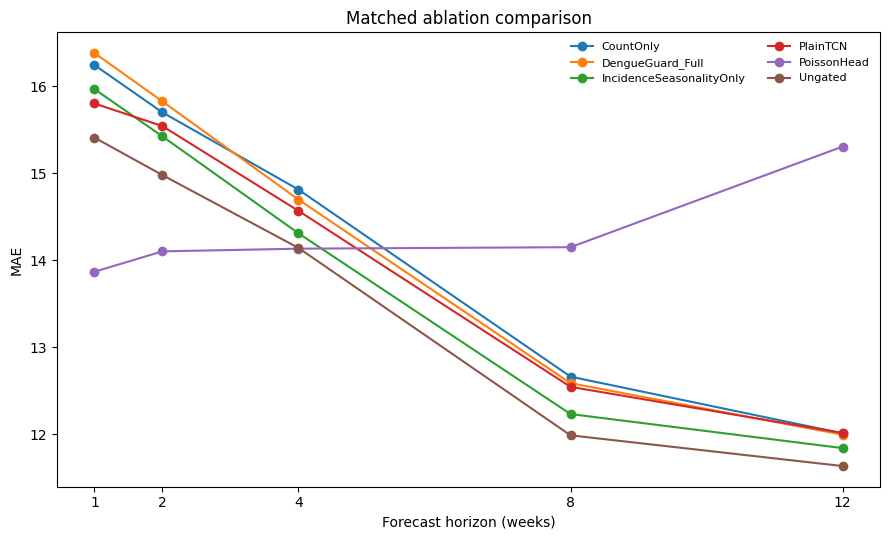

In [ ]:
fig,ax=plt.subplots(figsize=(9,5.5)); mean_ab=ablation_metrics.groupby(["model","horizon"],as_index=False).MAE.mean()
for model,d in mean_ab.groupby("model"): ax.plot(d.horizon,d.MAE,marker="o",label=model)
ax.set_xticks(HORIZONS); ax.set_xlabel("Forecast horizon (weeks)"); ax.set_ylabel("MAE"); ax.set_title("Matched ablation comparison"); ax.legend(frameon=False,fontsize=8,ncol=2)
fig.tight_layout(); fig.savefig(OUTPUT/"Fig_R1_ablation_MAE.png",dpi=600,bbox_inches="tight"); plt.show()

## 5. Matched historical baselines
The revised controls use historical information: **HGB_History52** on the flattened 52-week sequence, **PoissonRegression_History** on full-window summaries, **GRU_NB** on the same 52-week sequence, plus persistence and seasonal-naive. Hyperparameters for the classical learned baselines are selected using validation MAE only.

In [ ]:
baseline_predictions=[]; tuning_audits=[]; base_test=[s for s in samples if s.split=="test"]
pers=np.stack([s.persistence for s in base_test]); seas=np.stack([s.seasonal for s in base_test])
baseline_predictions.append(baseline_prediction_table(base_test,HORIZONS,"Persistence",pers,-1,0)); baseline_predictions.append(baseline_prediction_table(base_test,HORIZONS,"SeasonalNaive",seas,-1,0))
hgb_grid=[{"learning_rate":lr,"max_leaf_nodes":leaf,"l2_regularization":l2,"max_iter":it} for lr in ([.07] if QUICK_MODE else [.03,.07]) for leaf in ([31] if QUICK_MODE else [15,31]) for l2 in ([1.] if QUICK_MODE else [0.,1.]) for it in ([100] if QUICK_MODE else [200,400])]
hgb_models,hgb_audit=tune_hgb_history(samples,HORIZONS,seed=11,grid=hgb_grid,mode="flatten"); hgb_pred=predict_hgb_history(hgb_models,base_test,HORIZONS,"flatten"); baseline_predictions.append(baseline_prediction_table(base_test,HORIZONS,"HGB_History52",hgb_pred,-1,0,"poisson")); tuning_audits.append(hgb_audit)
pois_models,pois_audit=tune_poisson_history(samples,HORIZONS,alphas=([.1] if QUICK_MODE else [0.,.01,.1,1.]),mode="summary"); pois_pred=predict_poisson_history(pois_models,base_test,HORIZONS,"summary"); baseline_predictions.append(baseline_prediction_table(base_test,HORIZONS,"PoissonRegression_History",pois_pred,-1,0,"poisson")); tuning_audits.append(pois_audit)
for seed in SEEDS:
    gru=GRUForecastModel(len(feature_cols),len(HORIZONS),64,.2,True); gru,hist=train_neural_model(samples,gru,CFG,seed,DEVICE,"negative_binomial",True); mu,disp,prob,_=predict_neural(gru,base_test,DEVICE); baseline_predictions.append(make_neural_prediction_table("GRU_NB",base_test,mu,disp,prob,HORIZONS,seed,0,"negative_binomial"))
baseline_predictions=pd.concat(baseline_predictions,ignore_index=True); pd.concat(tuning_audits,ignore_index=True).to_csv(OUTPUT/"R3_baseline_tuning_audit.csv",index=False); baseline_predictions.to_csv(OUTPUT/"R3_baseline_predictions.csv",index=False)
baseline_metrics=summarize_prediction_metrics(baseline_predictions,train_scale(samples)); baseline_metrics.to_csv(OUTPUT/"R3_baseline_metrics.csv",index=False); display(baseline_metrics.groupby(["model","horizon"])[["MAE","RMSE","MASE"]].mean().round(4))

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_glm/glm.py:285: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  self.n_iter_ = _check_optimize_result("lbfgs", opt_res)
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_glm/glm.py:285: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  self.n_iter_ = _check_optimize_result("lbfgs", opt_res)
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_glm/glm.py:285: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data 

MAE      RMSE     MASE
model                     horizon                             
GRU_NB                    1         15.4104   31.1205   1.7995
                          2         15.0438   30.8256   1.7567
                          4         14.0556   28.9834   1.6413
                          8         12.0439   24.7534   1.4064
                          12        11.6219   23.9478   1.3571
HGB_History52             1         10.1054   16.4283   1.1800
                          2         12.4129   20.2169   1.4495
                          4         16.3462   27.8156   1.9088
                          8         20.7699   34.0463   2.4254
                          12        30.0459   49.9270   3.5086
Persistence               1          6.1970   10.8103   0.7236
                          2          8.2121   14.2903   0.9590
                          4         11.6717   21.3656   1.3629
                          8         16.6010   28.6267   1.9386
                          12        20.5859   35.1058   2.4039
PoissonRegression_History 1         39.9769   55.4548   4.6682
                          2         51.2632   74.6432   5.9862
                          4         62.7930   96.6418   7.3326
                          8        117.5079  188.2562  13.7218
                          12       153.4605  273.7058  17.9201
SeasonalNaive             1         22.7020   38.4863   2.6510
                          2         22.3030   38.1863   2.6044
                          4         21.0051   36.4350   2.4528
                          8         19.1414   33.1577   2.2352
                          12        18.3081   32.6848   2.1379

## 6. Negative-binomial probabilistic assessment
Report held-out negative log score, discrete CRPS, randomized PIT, and predictive intervals. This evaluates the NB head itself, separately from conformal calibration.

In [ ]:
prob_cols=["model","seed","horizon","log_score","discrete_crps","MAE","RMSE"]; prob_table=ablation_metrics[prob_cols].dropna(subset=["log_score"]); prob_table.to_csv(OUTPUT/"R5_probabilistic_scores.csv",index=False); display(prob_table.groupby(["model","horizon"])[["log_score","discrete_crps"]].mean().round(4))
pit_rows=[]
for model_name,dist in [("DengueGuard_Full","negative_binomial"),("PoissonHead","poisson")]:
    d0=ablation_predictions[ablation_predictions.model==model_name]
    for (seed,h),d in d0.groupby(["seed","horizon"]):
        pits=randomized_pit(d.actual.to_numpy(),d.predicted.to_numpy(),d.dispersion.to_numpy(),dist,seed=int(seed)+int(h)); pit_rows += [{"model":model_name,"seed":seed,"horizon":h,"PIT":v} for v in pits]
pit_df=pd.DataFrame(pit_rows); pit_df.to_csv(OUTPUT/"R5_randomized_PIT_values.csv",index=False)
for h in HORIZONS:
    fig,ax=plt.subplots(figsize=(7,4))
    for model,d in pit_df[pit_df.horizon==h].groupby("model"): ax.hist(d.PIT,bins=np.linspace(0,1,11),alpha=.45,density=True,label=model)
    ax.axhline(1,ls="--",lw=1); ax.set_xlim(0,1); ax.set_xlabel("Randomized PIT"); ax.set_ylabel("Density"); ax.set_title(f"Predictive-distribution PIT — {h} weeks"); ax.legend(frameon=False)
    fig.tight_layout(); fig.savefig(OUTPUT/f"Fig_R5_PIT_h{h}.png",dpi=600,bbox_inches="tight"); plt.close(fig)

log_score  discrete_crps
model                    horizon                          
CountOnly                1           4.0529        14.7660
                         2           4.0254        14.2926
                         4           4.0360        13.5855
                         8           3.9794        11.5964
                         12          3.9526        10.7207
DengueGuard_Full         1           4.0869        14.9749
                         2           4.0571        14.4616
                         4           4.0192        13.3939
                         8           3.9655        11.5455
                         12          3.9523        10.7075
IncidenceSeasonalityOnly 1           4.0854        14.8245
                         2           4.0943        14.3717
                         4           4.0708        13.3569
                         8           4.0543        11.3673
                         12          4.1552        10.9249
PlainTCN                 1           4.0303        13.9203
                         2           4.0404        13.6994
                         4           4.0204        13.0413
                         8           3.9032        11.0496
                         12          3.8625        10.3546
PoissonHead              1           9.1539        12.0140
                         2           9.3941        12.2641
                         4           9.6470        12.2821
                         8          10.2441        12.2884
                         12         12.2634        13.4054
Ungated                  1           3.9574        13.7571
                         2           3.9497        13.4030
                         4           3.9503        12.6156
                         8           3.8426        10.7137
                         12          3.7937         9.9349

## 7. Conformal and predictive-interval comparison
Compare: (1) uncalibrated NB predictive interval, (2) pooled horizon-specific residual conformal, (3) city-conditional residual conformal, and (4) sequential rolling residual calibration with a pre-specified 52-score window. Report coverage with Wilson CI, width, interval score, radii, and calibration counts by city × horizon.

In [ ]:
interval_rows=[]; interval_summaries=[]
for seed in SEEDS:
    c=full_cache[seed]; rows,summ=build_interval_comparison(c["cal"],c["cal_mu"],c["test"],c["test_mu"],c["test_disp"],HORIZONS,"negative_binomial",.90,52); rows["seed"]=seed; summ["seed"]=seed; interval_rows.append(rows); interval_summaries.append(summ)
interval_rows=pd.concat(interval_rows,ignore_index=True); interval_summaries=pd.concat(interval_summaries,ignore_index=True); interval_rows.to_csv(OUTPUT/"R6_interval_rows.csv",index=False); interval_summaries.to_csv(OUTPUT/"R6_interval_comparison.csv",index=False); display(interval_summaries.groupby(["method","city","horizon"])[["coverage","mean_width","interval_score"]].mean().round(4))
for city in sorted(interval_summaries.city.unique()):
    fig,ax=plt.subplots(figsize=(8,5)); m=interval_summaries[interval_summaries.city==city].groupby(["method","horizon"],as_index=False).coverage.mean()
    for method,d in m.groupby("method"): ax.plot(d.horizon,d.coverage,marker="o",label=method)
    ax.axhline(.90,ls="--",lw=1); ax.set_ylim(.5,1.05); ax.set_xticks(HORIZONS); ax.set_xlabel("Forecast horizon (weeks)"); ax.set_ylabel("Observed coverage"); ax.set_title(f"Interval coverage — {city}"); ax.legend(frameon=False,fontsize=8)
    fig.tight_layout(); fig.savefig(OUTPUT/f"Fig_R6_coverage_{city}.png",dpi=600,bbox_inches="tight"); plt.close(fig)

coverage  mean_width  \
method                       city horizon                         
adaptive_rolling             iq   1          0.9801     28.3856   
                                  2          0.9851     30.1717   
                                  4          0.9801     36.3974   
                                  8          0.9751     35.1129   
                                  12         0.9751     33.5414   
                             sj   1          0.8041     75.3490   
                                  2          0.8168     75.4397   
                                  4          0.8142     61.6078   
                                  8          0.8015     52.6599   
                                  12         0.8422     55.2034   
city_conformal               iq   1          1.0000     34.5995   
                                  2          1.0000     36.5621   
                                  4          1.0000     42.3317   
                                  8          1.0000     43.9744   
                                  12         1.0000     43.9553   
                             sj   1          0.7252     29.2268   
                                  2          0.7328     29.1498   
                                  4          0.7481     28.8199   
                                  8          0.7786     30.8898   
                                  12         0.8346     35.1063   
negative_binomial_predictive iq   1          0.9303     21.9900   
                                  2          0.9254     22.2537   
                                  4          0.9154     21.0945   
                                  8          0.9602     19.6269   
                                  12         0.9403     20.4378   
                             sj   1          0.8041     35.3893   
                                  2          0.8041     37.0941   
                                  4          0.8142     38.3130   
                                  8          0.8295     37.2977   
                                  12         0.8473     40.0076   
pooled_conformal             iq   1          0.9652     28.4955   
                                  2          0.9701     28.9316   
                                  4          0.9851     30.7745   
                                  8          1.0000     31.4247   
                                  12         1.0000     34.8174   
                             sj   1          0.7252     29.8988   
                                  2          0.7328     30.5443   
                                  4          0.7634     32.7481   
                                  8          0.7913     33.4119   
                                  12         0.8448     37.1208   

                                           interval_score  
method                       city horizon                  
adaptive_rolling             iq   1               28.9224  
                                  2               30.6644  
                                  4               36.8317  
                                  8               35.9718  
                                  12              34.4508  
                             sj   1              206.1966  
                                  2              206.2680  
                                  4              184.0062  
                                  8              136.7224  
                                  12             120.3737  
city_conformal               iq   1               34.5995  
                                  2               36.5621  
                                  4               42.3317  
                                  8               43.9744  
                                  12              43.9553  
                             sj   1              282.4910  
                                  2              274.5547  
                                  4              246.9755  
                            

## 8. Outbreak-probability reliability and threshold sensitivity
The implemented outbreak rule is `future_cases >= city_training_75th_percentile`, with linear interpolation. Add Brier score, log loss, ECE, city event counts, an incidence/seasonality logistic risk baseline, and count-derived NB risk probabilities for 70th/75th/80th percentile definitions.

In [ ]:
full_pred=ablation_predictions[ablation_predictions.model=="DengueGuard_Full"].copy(); out_metrics=outbreak_metric_table(full_pred)
risk_frames=[]
for seed in SEEDS:
    test=[s for s in samples if s.split=="test"]; probs=incidence_risk_baseline(samples,HORIZONS,seed); rows=[]
    for i,s in enumerate(test):
        for j,h in enumerate(HORIZONS): rows.append({"model":"IncidenceRiskBaseline","seed":seed,"fold":0,"city":s.city,"horizon":h,"outbreak_actual":int(s.outbreak[j]),"outbreak_probability":float(probs[i,j])})
    risk_frames.append(pd.DataFrame(rows))
risk_pred=pd.concat(risk_frames,ignore_index=True); risk_metrics=outbreak_metric_table(risk_pred); out_all=pd.concat([out_metrics,risk_metrics],ignore_index=True); out_all.to_csv(OUTPUT/"R7_outbreak_metrics.csv",index=False); display(out_all.groupby(["model","city","horizon"])[["events","prevalence","AUROC","AUPRC","Brier","log_loss","ECE_10"]].mean().round(4))
training_parts={}
for city,part in engineered.groupby("city",sort=True):
    part=part.sort_values(["year","weekofyear"]).reset_index(drop=True); train_end,_,_,_=split_boundaries_fraction(len(part),CFG["data"]); training_parts[str(city)]=part.loc[:train_end-1,"total_cases"]
sens=[]
for seed in SEEDS:
    c=full_cache[seed]; x=threshold_sensitivity_from_count(c["test"],c["test_mu"],c["test_disp"],training_parts,(.70,.75,.80),"negative_binomial"); x["seed"]=seed; x["horizon"]=x.horizon_index.map(dict(enumerate(HORIZONS))); sens.append(x)
sens=pd.concat(sens,ignore_index=True); sens.to_csv(OUTPUT/"R7_threshold_sensitivity.csv",index=False)
for h in HORIZONS:
    fig,ax=plt.subplots(figsize=(5.5,5))
    for name,d in [("DengueGuard",full_pred[full_pred.horizon==h]),("Incidence baseline",risk_pred[risk_pred.horizon==h])]:
        bins=np.linspace(0,1,6); xs=[]; ys=[]
        for i in range(len(bins)-1):
            m=(d.outbreak_probability>=bins[i])&(d.outbreak_probability < bins[i+1] if i<len(bins)-2 else d.outbreak_probability<=bins[i+1])
            if m.any(): xs.append(float(d.loc[m,"outbreak_probability"].mean())); ys.append(float(d.loc[m,"outbreak_actual"].mean()))
        ax.plot(xs,ys,marker="o",label=name)
    ax.plot([0,1],[0,1],ls="--",lw=1); ax.set_xlabel("Mean predicted probability"); ax.set_ylabel("Observed event frequency"); ax.set_title(f"Outbreak reliability — {h} weeks"); ax.legend(frameon=False); fig.tight_layout(); fig.savefig(OUTPUT/f"Fig_R7_reliability_h{h}.png",dpi=600,bbox_inches="tight"); plt.close(fig)

events  prevalence   AUROC   AUPRC  \
model                 city horizon                                       
DengueGuard_Full      iq   1          26.0      0.3881  0.9049  0.8191   
                           2          27.0      0.4030  0.9037  0.8511   
                           4          25.0      0.3731  0.8527  0.8077   
                           8          22.0      0.3284  0.7397  0.5708   
                           12         18.0      0.2687  0.7105  0.5113   
                      sj   1          25.0      0.1908  0.9775  0.9095   
                           2          24.0      0.1832  0.9708  0.8495   
                           4          22.0      0.1679  0.9504  0.7405   
                           8          18.0      0.1374  0.8691  0.4287   
                           12         15.0      0.1145  0.7140  0.2280   
IncidenceRiskBaseline iq   1          26.0      0.3881  0.8898  0.8537   
                           2          27.0      0.4030  0.7935  0.7316   
                           4          25.0      0.3731  0.6262  0.4889   
                           8          22.0      0.3284  0.4677  0.2958   
                           12         18.0      0.2687  0.5136  0.3090   
                      sj   1          25.0      0.1908  0.9879  0.9542   
                           2          24.0      0.1832  0.9829  0.9366   
                           4          22.0      0.1679  0.9625  0.8224   
                           8          18.0      0.1374  0.8670  0.4228   
                           12         15.0      0.1145  0.7615  0.2164   

                                     Brier  log_loss  ECE_10  
model                 city horizon                            
DengueGuard_Full      iq   1        0.1543    0.4759  0.1820  
                           2        0.1592    0.4808  0.1675  
                           4        0.1720    0.5192  0.1517  
                           8        0.1969    0.5731  0.1052  
                           12       0.1830    0.5496  0.1110  
                      sj   1        0.0990    0.3180  0.1521  
                           2        0.1120    0.3584  0.1681  
                           4        0.1337    0.4260  0.1909  
                           8        0.1795    0.5599  0.2321  
                           12       0.2111    0.6203  0.2546  
IncidenceRiskBaseline iq   1        0.2594    0.7215  0.2427  
                           2        0.2786    0.7753  0.2977  
                           4        0.2704    0.7633  0.2373  
                           8        0.2583    0.7454  0.2040  
                           12       0.2196    0.6407  0.1812  
                      sj   1        0.0606    0.2493  0.1594  
                           2        0.0687    0.2701  0.1773  
                           4        0.0873    0.3231  0.1750  
                           8        0.1279    0.4173  0.1812  
                           12       0.1361    0.4306  0.1910

## 9. Dependence-aware paired moving-block bootstrap
Use a city-aware moving-block procedure with the **same resampled origin blocks across all horizons and models**, block-length sensitivity 4/8/12 weeks, and Holm multiplicity adjustment. Primary comparisons use seed-mean neural predictions so random initializations do not pseudo-replicate the same epidemic period.

In [ ]:
all_pred=pd.concat([ablation_predictions[ablation_predictions.model=="DengueGuard_Full"],baseline_predictions],ignore_index=True); keys=["model","city","origin_year","origin_week","horizon","actual"]; mean_pred=all_pred.groupby(keys,as_index=False).predicted.mean(); mean_pred["seed"]=-99; mean_pred["fold"]=0
wanted=["DengueGuard_Full","Persistence","SeasonalNaive","HGB_History52","GRU_NB"]; mb_input=mean_pred[mean_pred.model.isin(wanted)].copy(); mb_tables=[]
for L in ([4] if QUICK_MODE else [4,8,12]):
    out=city_moving_block_bootstrap(mb_input,"DengueGuard_Full",[m for m in wanted if m!="DengueGuard_Full"],HORIZONS,L,CFG["evaluation"]["bootstrap_repetitions"],2026+L); mb_tables.append(out)
mb=pd.concat(mb_tables,ignore_index=True); mb.to_csv(OUTPUT/"R4_block_bootstrap.csv",index=False); display(mb.round(4))

,horizon,comparison,block_length,test_origins,approx_effective_blocks,MAE_difference,CI_low,CI_high,bootstrap_two_sided_p,holm_adjusted_p
0,1,DengueGuard_Full - Persistence,4,198,48,10.1269,4.5759,16.0158,0.000,0.000
1,1,DengueGuard_Full - SeasonalNaive,4,198,48,-6.3781,-12.1469,-1.5902,0.002,0.026
2,1,DengueGuard_Full - HGB_History52,4,198,48,6.2185,0.9355,11.5798,0.016,0.128
3,1,DengueGuard_Full - GRU_NB,4,198,48,1.0340,0.2706,1.8542,0.008,0.072
4,2,DengueGuard_Full - Persistence,4,198,48,7.5535,2.4487,12.5628,0.000,0.000
5,2,DengueGuard_Full - SeasonalNaive,4,198,48,-6.5374,-12.2325,-1.7633,0.001,0.015
6,2,DengueGuard_Full - HGB_History52,4,198,48,3.3527,-1.9205,8.7980,0.234,0.936
7,2,DengueGuard_Full - GRU_NB,4,198,48,0.8880,0.2979,1.5218,0.004,0.044
8,4,DengueGuard_Full - Persistence,4,198,48,2.9635,-1.8048,7.5628,0.272,0.936
9,4,DengueGuard_Full - SeasonalNaive,4,198,48,-6.3699,-12.3423,-2.0466,0.000,0.000


## 10. Repeated chronological forecast-origin evaluation
Three expanding-window folds are formed per city. Each fold uses 26 weeks validation, 52 weeks calibration, and 52 weeks test, with non-overlapping test periods separated by 52 weeks. Primary repeated-origin comparisons: DengueGuard, GRU-NB, history-matched HGB, persistence, and seasonal-naive.

In [16]:
ROLLING_FOLDS=1 if QUICK_MODE else 3; rolling_predictions=[]; rolling_split_audits=[]
for fold in range(ROLLING_FOLDS):
    print("\nROLLING FOLD",fold); boundaries={str(city):rolling_boundaries(len(part),fold,52,52,26,52) for city,part in engineered.groupby("city")}
    rs_raw,rs_th,rs_audit,rs_manifest=build_samples(engineered,feature_cols,CFG["data"],fold,boundaries); rs,rs_scaler,rs_med=impute_and_scale(rs_raw); rolling_split_audits.append(rs_audit); test=[s for s in rs if s.split=="test"]
    rolling_predictions.append(baseline_prediction_table(test,HORIZONS,"Persistence",np.stack([s.persistence for s in test]),-1,fold)); rolling_predictions.append(baseline_prediction_table(test,HORIZONS,"SeasonalNaive",np.stack([s.seasonal for s in test]),-1,fold))
    hgb,ha=tune_hgb_history(rs,HORIZONS,11,hgb_grid,"flatten"); hp=predict_hgb_history(hgb,test,HORIZONS,"flatten"); rolling_predictions.append(baseline_prediction_table(test,HORIZONS,"HGB_History52",hp,-1,fold,"poisson"))
    for seed in SEEDS:
        full=TemporalForecastModel(len(feature_cols),len(HORIZONS),CFG["model"],True,True,"negative_binomial",True); full,_=train_neural_model(rs,full,CFG,seed,DEVICE,"negative_binomial",True); mu,disp,prob,_=predict_neural(full,test,DEVICE); rolling_predictions.append(make_neural_prediction_table("DengueGuard_Full",test,mu,disp,prob,HORIZONS,seed,fold,"negative_binomial"))
        gru=GRUForecastModel(len(feature_cols),len(HORIZONS),64,.2,True); gru,_=train_neural_model(rs,gru,CFG,seed,DEVICE,"negative_binomial",True); mu,disp,prob,_=predict_neural(gru,test,DEVICE); rolling_predictions.append(make_neural_prediction_table("GRU_NB",test,mu,disp,prob,HORIZONS,seed,fold,"negative_binomial"))
rolling_predictions=pd.concat(rolling_predictions,ignore_index=True); rolling_split_audits=pd.concat(rolling_split_audits,ignore_index=True); rolling_predictions.to_csv(OUTPUT/"R2_temporal_replication_predictions.csv",index=False); rolling_split_audits.to_csv(OUTPUT/"R2_temporal_replication_split_audit.csv",index=False)
rolling_metrics=summarize_prediction_metrics(rolling_predictions,train_scale(samples)); rolling_metrics.to_csv(OUTPUT/"R2_temporal_replication_metrics.csv",index=False)
city_roll=[]
for k,d in rolling_predictions.groupby(["model","seed","fold","city","horizon"]): city_roll.append({"model":k[0],"seed":k[1],"fold":k[2],"city":k[3],"horizon":k[4],"n":len(d),"MAE":mean_absolute_error(d.actual,d.predicted)})
city_roll=pd.DataFrame(city_roll); city_roll.to_csv(OUTPUT/"R2_temporal_replication_city_MAE.csv",index=False); display(city_roll.groupby(["model","fold","city","horizon"]).MAE.mean().round(3).head(100))


ROLLING FOLD 0

ROLLING FOLD 1

ROLLING FOLD 2


model             fold  city  horizon
DengueGuard_Full  0     iq    1           3.725
                              2           3.848
                              4           4.145
                              8           3.786
                              12          4.185
                                          ...  
Persistence       0     sj    1          11.585
                              2          15.878
                              4          23.927
                              8          40.317
                              12         51.146
Name: MAE, Length: 100, dtype: float64

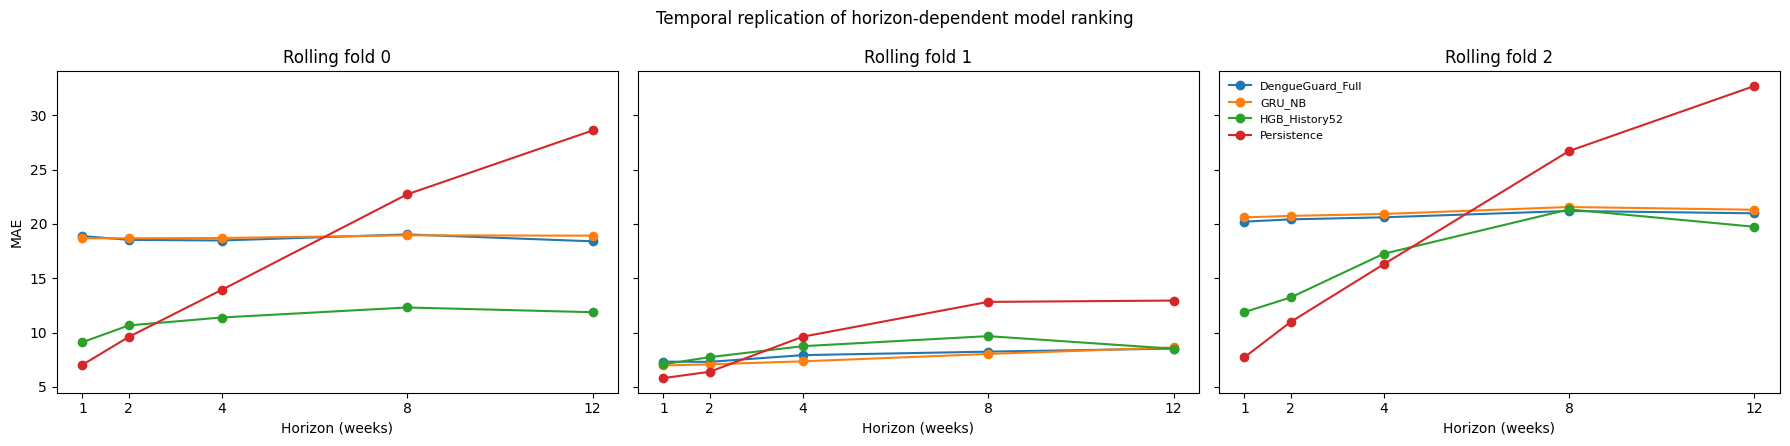

In [17]:
fig,axes=plt.subplots(1,ROLLING_FOLDS,figsize=(6*ROLLING_FOLDS,4.5),sharey=True); axes=[axes] if ROLLING_FOLDS==1 else axes
for fold,ax in enumerate(axes):
    d=rolling_predictions[(rolling_predictions.fold==fold)&(rolling_predictions.model.isin(["DengueGuard_Full","Persistence","HGB_History52","GRU_NB"]))]
    rows=[]
    for (model,h),g in d.groupby(["model","horizon"]): rows.append({"model":model,"horizon":h,"MAE":mean_absolute_error(g.actual,g.predicted)})
    m=pd.DataFrame(rows)
    for model,g in m.groupby("model"): ax.plot(g.horizon,g.MAE,marker="o",label=model)
    ax.set_xticks(HORIZONS); ax.set_xlabel("Horizon (weeks)"); ax.set_title(f"Rolling fold {fold}");
    if fold==0: ax.set_ylabel("MAE")
axes[-1].legend(frameon=False,fontsize=8); fig.suptitle("Temporal replication of horizon-dependent model ranking"); fig.tight_layout(); fig.savefig(OUTPUT/"Fig_R2_temporal_replication.png",dpi=600,bbox_inches="tight"); plt.show()

## 11. Reporting-delay sensitivity
The benchmark is retrospective and does not provide true release/revision timestamps. Therefore, do not claim every covariate was available in real time. Evaluate primary availability, +1-week case delay, +1-week environmental delay, +1-week delay for both, and +2-week delay for both.

In [18]:
delay_scenarios={"primary":(0,0),"case_delay_1w":(1,0),"environment_delay_1w":(0,1),"both_delay_1w":(1,1),"both_delay_2w":(2,2)}; delay_rows=[]; DELAY_SEEDS=[11] if QUICK_MODE else SEEDS
for scenario,(case_delay,env_delay) in delay_scenarios.items():
    eng,fc=engineer_frame(raw,case_delay,env_delay); ss_raw,_,_,_=build_samples(eng,fc,CFG["data"],0); ss,_,_=impute_and_scale(ss_raw); test=[s for s in ss if s.split=="test"]
    for seed in DELAY_SEEDS:
        model=TemporalForecastModel(len(fc),len(HORIZONS),CFG["model"],True,True,"negative_binomial",True); model,_=train_neural_model(ss,model,CFG,seed,DEVICE,"negative_binomial",True); mu,disp,prob,_=predict_neural(model,test,DEVICE); pred=make_neural_prediction_table(scenario,test,mu,disp,prob,HORIZONS,seed,0,"negative_binomial"); met=summarize_prediction_metrics(pred,train_scale(ss)); met["scenario"]=scenario; met["case_delay_weeks"]=case_delay; met["environmental_delay_weeks"]=env_delay; delay_rows.append(met)
delay_metrics=pd.concat(delay_rows,ignore_index=True); delay_metrics.to_csv(OUTPUT/"R9_delay_sensitivity.csv",index=False); display(delay_metrics.groupby(["scenario","horizon"])[["MAE","RMSE"]].mean().round(3))

MAE    RMSE
scenario             horizon                
both_delay_1w        1        15.844  32.422
                     2        15.509  32.101
                     4        14.405  29.835
                     8        12.627  26.163
                     12       11.927  25.119
both_delay_2w        1        15.456  31.470
                     2        15.080  31.142
                     4        14.134  29.221
                     8        12.114  25.242
                     12       11.675  24.660
case_delay_1w        1        15.685  31.778
                     2        15.302  31.427
                     4        14.242  29.170
                     8        12.430  25.508
                     12       11.885  24.927
environment_delay_1w 1        15.713  31.984
                     2        15.459  31.825
                     4        14.310  29.586
                     8        12.194  25.223
                     12       11.792  24.594
primary              1        15.777  32.012
                     2        15.555  31.881
                     4        14.631  29.826
                     8        12.592  25.902
                     12       11.944  24.625

## 12. Reproducibility artifact
Package exact configuration, feature order, split indices, fitted preprocessing statistics, tuning audits, per-origin predictions, calibration outputs, and reviewer-analysis tables. Upload the resulting ZIP to a versioned GitHub Release and/or Zenodo DOI. The SHA-256 fingerprint verifies the exact archive.

In [19]:
response_map=pd.DataFrame([
["R1-1 / R2-1","Matched TCN and component ablations","R1_ablation_metrics.csv; Fig_R1_ablation_MAE.png"],
["R1-2","Exact split dates, indices, fitted preprocessing periods","R2_split_audit.csv; R2_origin_target_manifest.csv; R2_fitted_preprocessing_statistics.csv"],
["R1-3","History-matched baselines and tuning","R3_baseline_metrics.csv; R3_baseline_tuning_audit.csv"],
["R1-4","City-aware moving-block bootstrap, sensitivity, Holm multiplicity","R4_block_bootstrap.csv"],
["R1-5","NB/Poisson probabilistic scores and PIT","R5_probabilistic_scores.csv; R5_randomized_PIT_values.csv"],
["R1-6","Pooled/city/adaptive interval comparison","R6_interval_comparison.csv"],
["R1-7","Outbreak Brier/log/ECE, risk baseline, threshold sensitivity","R7_outbreak_metrics.csv; R7_threshold_sensitivity.csv"],
["R1-8","Layer shapes, normalization, dropout, parameters, receptive field","R8_architecture_audit.csv"],
["R1-9 / R2-4","32-feature manifest and reporting-delay sensitivity","R9_feature_manifest.csv; R9_delay_sensitivity.csv"],
["R2-2","Repeated chronological forecast origins","R2_temporal_replication_metrics.csv; R2_temporal_replication_city_MAE.csv"]],columns=["reviewer_comment","analysis","evidence"])
response_map.to_csv(OUTPUT/"Reviewer_Response_Evidence_Map.csv",index=False)
readme=f"""DengueGuard IJIES Major Revision Artifact
Paper ID: 20267240
Seeds: {SEEDS}
Horizons: {HORIZONS}
Device: {DEVICE}

Interpretation constraints:
- Internal two-city retrospective benchmark only.
- Equality counts as outbreak (cases >= training-derived threshold).
- 75th percentile uses linear interpolation.
- Retrospective environmental covariates do not encode real-time publication/revision latency.
- Moving-block bootstrap is the dependence-aware primary paired uncertainty analysis.
"""
(OUTPUT/"README_ARTIFACT.txt").write_text(readme)
zip_base=Path("/content/DengueGuard_IJIES_R1_Reproducibility_Artifact");
if zip_base.with_suffix(".zip").exists(): zip_base.with_suffix(".zip").unlink()
shutil.make_archive(str(zip_base),"zip",OUTPUT); sha=sha256_file(zip_base.with_suffix(".zip")); save_json({"artifact":zip_base.with_suffix(".zip").name,"sha256":sha,"seeds":SEEDS,"horizons":HORIZONS},OUTPUT/"artifact_verification.json")
print("Artifact:",zip_base.with_suffix(".zip")); print("SHA-256:",sha); display(response_map)

Artifact: /content/DengueGuard_IJIES_R1_Reproducibility_Artifact.zip
SHA-256: 2913c0c924f0e6d2bdb0fee2276982ef459a825fcd35a4f50f0d3a4b63d99e3a


,reviewer_comment,analysis,evidence
0,R1-1 / R2-1,Matched TCN and component ablations,R1_ablation_metrics.csv; Fig_R1_ablation_MAE.png
1,R1-2,"Exact split dates, indices, fitted preprocessi...",R2_split_audit.csv; R2_origin_target_manifest....
2,R1-3,History-matched baselines and tuning,R3_baseline_metrics.csv; R3_baseline_tuning_au...
3,R1-4,"City-aware moving-block bootstrap, sensitivity...",R4_block_bootstrap.csv
4,R1-5,NB/Poisson probabilistic scores and PIT,R5_probabilistic_scores.csv; R5_randomized_PIT...
5,R1-6,Pooled/city/adaptive interval comparison,R6_interval_comparison.csv
6,R1-7,"Outbreak Brier/log/ECE, risk baseline, thresho...",R7_outbreak_metrics.csv; R7_threshold_sensitiv...
7,R1-8,"Layer shapes, normalization, dropout, paramete...",R8_architecture_audit.csv
8,R1-9 / R2-4,32-feature manifest and reporting-delay sensit...,R9_feature_manifest.csv; R9_delay_sensitivity.csv
9,R2-2,Repeated chronological forecast origins,R2_temporal_replication_metrics.csv; R2_tempor...
